# D04 — Real-Damage Restoration and Evaluation

**Origin:** New Notebook — approved real-damage supplement  
**Refactor status:** Finished                                   
**Validation status:** Finished                                          
**Completion gate passed:** Yes                                
**Output root:** `outputs/d04_real_damage_restoration_and_evaluation/`  
**Depends on:** Completed D03; existing four-model restoration helpers and saved Controlled-300 evidence

## Purpose

Apply the existing four restoration methods to ten photographs of physically
damaged paintings using D03's reviewed repair masks. Examine the restorations
through visual comparisons, reference-free diagnostics and repeated-seed
variation.

This supplement remains separate from the completed Controlled-300 study.

## Population and restoration methods

The dataset contains ten paintings, two per operational visual category.
The approved 768 × 768 RGB inputs and binary repair masks are reused without
further preprocessing or mask expansion.

OpenCV Telea, LaMa, HINT and Stable Diffusion provide 40 primary restorations.
Stable Diffusion also produces 30 additional candidates, forming ten
four-seed groups at seeds 2026, 2027, 2028 and 2029. Seed 2026 supplies the
primary SD candidate.

The existing model checkpoints and numerical generation settings are retained.
Stable Diffusion uses its existing 512-pixel inference and final masked
compositing at 768 pixels.

## Targeted Stable Diffusion prompts

Each painting receives one prompt based on its visible damaged input,
surrounding painted content and reviewed mask. The prompt catalog records
the observations, text and exact image/mask hashes.

This replaces the generic prompt proposed in D03 for downstream restoration.
D03's completed records remain unchanged; D04 records the amended policy
under a separate effective configuration identifier.

Each prompt remains fixed across the painting's four seeds. The existing
negative prompt is retained. Prompt-length validation and plan freezing
precede inference. No clean reference or restoration outcome is used to
author these prompts.

## Evidence and interpretation

The photographs have no known clean references. The damaged input is not
used as a substitute reference for restoration-accuracy scores.

Outside-mask checks measure preservation of existing pixels. Inside-mask
changes describe edit magnitude. Boundary measurements describe transitions
that require visual interpretation. Repeated-seed differences describe
variation, not calibrated confidence or reconstruction correctness.

The reviewed masks identify selected repair targets, not every visible
defect. Unselected deterioration may remain.

Ten existing synthetic cases will provide descriptive comparisons. Their
saved restorations remain unchanged, including generic-prompt SD outputs.
Consequently, these comparisons differ in prompt policy as well as damage
source. Physical and synthetic measurements remain separate.

## Batch sequence

1. D03 handoff and targeted-prompt preflight.
2. Runtime readiness, prompt-length checks and synthetic comparator selection.
3. Telea smoke check and ten restorations.
4. LaMa smoke check and ten restorations.
5. HINT smoke check and ten restorations.
6. Targeted-prompt primary Stable Diffusion.
7. Fixed-prompt repeated-seed Stable Diffusion.
8. Diagnostics and seed variability.
9. Physical and synthetic comparison.
10. Reporting and completion gate.

## Canonical outputs

All paths below are relative to the notebook output root.

- `data/candidate_plan.csv` and `data/candidates.csv`
- `data/prompt_policy.csv` and `data/model_provenance.csv`
- `data/synthetic_comparators.csv` and `data/case_observations.csv`
- `metrics/runtime_summary.csv` and `metrics/technical_checks.csv`
- `metrics/real_damage_diagnostics.csv`
- `metrics/seed_pairwise.csv` and `metrics/uncertainty_summary.csv`
- `metrics/synthetic_comparison.csv`
- `images/restored/` and `images/uncertainty/`
- `figures/case_comparisons/`, `figures/synthetic_comparisons/`
  and `figures/seed_variability/`
- `validation/checks.csv`
- `manifests/run_manifest.json` and `manifests/artifacts.csv`

The standalone illustrated report is
`reports/real_damage_evaluation.html`.

Resume checkpoints and execution logs belong to `work/` and `logs/`.
Completion requires validated outputs and provenance; an unattractive
restoration is retained as an experimental result.

## Batch 1 — D03 handoff and targeted-prompt preflight

Verify the completed D03 package, approved images and masks, current
inventory, original model configurations and targeted-prompt bindings.

Construct an in-memory preview of the 70-candidate design and display the
ten proposed prompts. The preview does not constitute a frozen execution
plan.

This batch is read-only. It does not load model weights, check GPU readiness,
generate restorations or write D04 artifacts. Runtime validation, tokenizer
checks and plan freezing belong to Batch 2.

In [1]:
from pathlib import Path
import importlib
import sys

import pandas as pd
from IPython.display import display, Markdown

for batch_number in range(1, 11):
    globals()[f"D04_BATCH_{batch_number}_READY"] = False

START_DIRECTORY = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (START_DIRECTORY, *START_DIRECTORY.parents)
        if (candidate / ".git").exists()
        and (candidate / "src" / "restoration_eval").is_dir()
        and (candidate / "notebooks").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Could not locate the repository from {START_DIRECTORY}"
    )

SRC_ROOT = PROJECT_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from restoration_eval import manifests, real_damage_restoration

d04 = importlib.reload(real_damage_restoration)

EXPECTED_HELPER = (
    SRC_ROOT / "restoration_eval" / "real_damage_restoration.py"
).resolve()
if Path(d04.__file__).resolve() != EXPECTED_HELPER:
    raise RuntimeError("D04 helper was imported from another checkout.")

D04_CONFIG_PATH = (
    PROJECT_ROOT / "config/experiments/real_damage_restoration.yaml"
)
D04_CONFIG = d04.load_restoration_config(D04_CONFIG_PATH)

D04_RUN_STARTED_AT_UTC = manifests.utc_now_iso()
D04_ENVIRONMENT = manifests.environment_summary(
    package_names=["numpy", "pandas", "Pillow", "PyYAML"]
)
D04_GIT_STATE = manifests.git_state(PROJECT_ROOT)

display(pd.DataFrame([{
    "notebook": D04_CONFIG["notebook"]["id"],
    "dataset_scope": D04_CONFIG["dataset"]["dataset_scope"],
    "dataset_version": D04_CONFIG["dataset"]["dataset_version"],
    "helper_version": d04.REAL_DAMAGE_RESTORATION_MODULE_VERSION,
    "prompt_policy": D04_CONFIG["prompt_policy"]["policy_id"],
    "planned_candidates": D04_CONFIG["candidate_design"]["total_candidates"],
}]))

,notebook,dataset_scope,dataset_version,helper_version,prompt_policy,planned_candidates
0,D04,real_damage_10,2.0.0,1.0.0,d04_sd15_targeted_visible_context.v1,70


In [2]:
D04_BATCH_1_READY = False

D04_PREFLIGHT = d04.audit_restoration_preflight(
    PROJECT_ROOT,
    D04_CONFIG_PATH,
)

D04_VALIDATION = D04_PREFLIGHT["validation"]
D04_CHECKS = D04_VALIDATION.to_dataframe()

display(pd.DataFrame([D04_VALIDATION.summary()]))

D04_FAILED_CHECKS = D04_CHECKS.loc[~D04_CHECKS["passed"]]
if not D04_FAILED_CHECKS.empty:
    display(D04_FAILED_CHECKS[
        [
            "check_id",
            "check_description",
            "expected",
            "observed",
            "details",
        ]
    ])

D04_VALIDATION.raise_for_blocking()

D04_INPUTS = D04_PREFLIGHT["inputs"]
D04_OUTPUTS = D04_PREFLIGHT["outputs"]
D04_OUTPUT_ROOT = D04_PREFLIGHT["output_root"]
D04_INPUT_CHECKSUMS = D04_PREFLIGHT["input_checksums"]
D04_INVENTORY_RUN = D04_PREFLIGHT["inventory"]
D04_UPSTREAM_MANIFEST = D04_PREFLIGHT["upstream_manifest"]
D04_TABLES = D04_PREFLIGHT["tables"]
D04_PROMPTS = D04_PREFLIGHT["prompts"]
D04_CANDIDATE_PREVIEW = D04_PREFLIGHT["candidate_plan"]

D04_BATCH_1_READY = True

print("D03 run:", D04_UPSTREAM_MANIFEST["run_id"])
print(
    "D03 saved checks passed:",
    D04_UPSTREAM_MANIFEST["validation_summary"]["passed_count"],
)
print("Inventory run:", D04_INVENTORY_RUN["inventory_run_id"])
print("Verified input records:", len(D04_PREFLIGHT["input_audit"]))
print("Candidate plan status:", D04_PREFLIGHT["candidate_plan_status"])
print("Runtime status:", D04_PREFLIGHT["runtime_status"])
print("Tokenizer status:", D04_PREFLIGHT["tokenizer_status"])
print("Preflight seconds:", round(D04_PREFLIGHT["elapsed_seconds"], 2))

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,31,31,0,0,True,[]


D03 run: run_d03_6a2e02fcf9a4b65a612b7cdf
D03 saved checks passed: 379
Inventory run: inventory_20261115T013621Z_1e77b926
Verified input records: 53
Candidate plan status: preview_not_frozen
Runtime status: pending_batch_2
Tokenizer status: pending_batch_2
Preflight seconds: 14.75


In [3]:
if not D04_BATCH_1_READY:
    raise RuntimeError("D04 Batch 1 preflight has not passed.")

D04_POPULATION = (
    D04_TABLES["artworks"][
        ["painting_id", "title", "category", "license"]
    ]
    .merge(
        D04_TABLES["case_registry"][
            ["painting_id", "realized_damage_fraction"]
        ],
        on="painting_id",
        validate="one_to_one",
    )
)
D04_POPULATION["selected_repair_percent"] = (
    100 * D04_POPULATION.pop("realized_damage_fraction")
).round(3)

with pd.option_context("display.max_colwidth", 85):
    display(D04_POPULATION)

display(
    D04_CANDIDATE_PREVIEW.groupby(
        ["model_id", "candidate_role"], sort=False
    )
    .size()
    .rename("planned_candidates")
    .reset_index()
)

display(
    D04_CANDIDATE_PREVIEW[
        ["model_id", "baseline_configuration_id", "configuration_id"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

for row in D04_PROMPTS.itertuples(index=False):
    display(Markdown(
        f"### {row.painting_id} — {row.title}\n\n"
        f"**Observed repair context:** "
        f"{row.visible_damage_observation}\n\n"
        f"**Targeted SD prompt:** {row.prompt}\n\n"
        f"**Prompt identifier:** `{row.prompt_id}`"
    ))

D04_SD_PREVIEW = D04_CANDIDATE_PREVIEW.loc[
    D04_CANDIDATE_PREVIEW["model_id"].eq(
        "stable_diffusion_inpainting"
    )
]

display(Markdown(
    "**Shared negative prompt — unchanged from the SD baseline:**\n\n"
    + D04_SD_PREVIEW["negative_prompt"].iloc[0]
))

display(
    D04_SD_PREVIEW.groupby("painting_id", sort=True)
    .agg(
        candidates=("candidate_id", "size"),
        distinct_positive_prompts=("prompt", "nunique"),
        distinct_negative_prompts=("negative_prompt", "nunique"),
        seeds=("seed", lambda values: ", ".join(
            str(int(value)) for value in sorted(values)
        )),
    )
    .reset_index()
)

,painting_id,title,category,license,selected_repair_percent
0,rd001,Portrait of Antonio van Diemen,portrait_figure,Public domain,2.755
1,rd002,Antigone condemned to death by Creon — before restoration,portrait_figure,Public domain,3.499
2,rd003,Horse pasture in Algeria,landscape_natural,Public domain,7.209
3,rd004,"Garden fresco, House of the Golden Bracelet",landscape_natural,CC BY 2.0,6.371
4,rd005,Landscape with maritime villa,architecture_structured,CC BY-SA 4.0,2.159
5,rd006,"Cubiculum wall, Villa of P. Fannius Synistor",architecture_structured,CC0,2.736
6,rd007,Black Square,abstraction_surrealism,Public domain,7.827
7,rd008,Watermelon Regatta — damaged state,abstraction_surrealism,Public domain,2.025
8,rd009,Tarquinius and Lucretia — damaged state,high_texture_brushwork,Public domain,2.571
9,rd010,Nude — before restoration,high_texture_brushwork,Public domain,3.674


,model_id,candidate_role,planned_candidates
0,opencv_telea,primary,10
1,lama,primary,10
2,hint_places2,primary,10
3,stable_diffusion_inpainting,primary,10
4,stable_diffusion_inpainting,additional_seed,30


,model_id,baseline_configuration_id,configuration_id
0,opencv_telea,opencv_telea_r3_threshold_policy_v1,opencv_telea_r3_threshold_policy_v1
1,lama,lama_iopaint_masked_composite_v1,lama_iopaint_masked_composite_v1
2,hint_places2,hint_places2_native_768_exact_composite_v1,hint_places2_native_768_exact_composite_v1
3,stable_diffusion_inpainting,sd15_inpaint_fixed_policy_v1,sd15_inpaint_targeted_real_damage_v1


### rd001 — Portrait of Antonio van Diemen

**Observed repair context:** Vertical losses interrupt the dark hat, black clothing and reddish-brown background; the visible face and collar supply context.

**Targeted SD prompt:** An aged oil portrait, continuous black hat and dark clothing, warm reddish brown background and muted green side curtain. Fill the narrow gaps by continuing nearby painted tones, fabric contours and soft brushwork, preserving the existing figure and collar.

**Prompt identifier:** `d04_targeted_rd001_v1`

### rd002 — Antigone condemned to death by Creon — before restoration

**Observed repair context:** Selected flaking crosses the left cliff, pale sky, soldier and clothing; intact architecture, skin and metal have mask exclusions.

**Targeted SD prompt:** A classical figurative oil painting, pale cloudy sky above a rocky cliff, muted stone buildings and a soldier in armour beside draped figures. Continue the nearby rock contours, metal shading and coloured fabric folds across the missing patches with matching brushwork.

**Prompt identifier:** `d04_targeted_rd002_v1`

### rd003 — Horse pasture in Algeria

**Observed repair context:** The large right-hand tear crosses pale sky and green land; smaller left-edge losses cross the same landscape. Extensive unselected abrasion remains.

**Targeted SD prompt:** An aged landscape painting with a pale blue grey sky, low muted hills and green pasture. Continue the surrounding sky gradients, distant horizon and soft green earth tones through the missing areas, matching the subdued colours and fine existing painted texture.

**Prompt identifier:** `d04_targeted_rd003_v1`

... (5 outputs left out)

### rd009 — Tarquinius and Lucretia — damaged state

**Observed repair context:** Selected tear lines and scattered flakes cross dark background, drapery and figures; painted highlights are excluded where distinguishable.

**Targeted SD prompt:** A dramatic figurative oil painting with warm skin tones, deep brown shadows and richly folded red and cream fabrics. Continue nearby skin shading, drapery contours and dark background through the thin missing patches, matching the soft luminous paint and existing figure shapes.

**Prompt identifier:** `d04_targeted_rd009_v1`

### rd010 — Nude — before restoration

**Observed repair context:** Selected light flakes lie on the figure and dark surrounding field; global deterioration and photographic grain are not treated as missing painted content.

**Targeted SD prompt:** A subdued painted figure study, warm ochre skin against a dark green brown background, soft shadows and loose brushwork. Fill the scattered small gaps with nearby skin or background tones, continuing the existing contours and gentle tonal modelling at the same level of detail.

**Prompt identifier:** `d04_targeted_rd010_v1`

**Shared negative prompt — unchanged from the SD baseline:**

modern objects, text, watermark, signature, frame, border, added people, changed faces, extra objects, oversharpened, cartoon, digital art, photorealistic replacement, unrealistic texture, harsh seams

,painting_id,candidates,distinct_positive_prompts,distinct_negative_prompts,seeds
0,rd001,4,1,1,"2026, 2027, 2028, 2029"
1,rd002,4,1,1,"2026, 2027, 2028, 2029"
2,rd003,4,1,1,"2026, 2027, 2028, 2029"
3,rd004,4,1,1,"2026, 2027, 2028, 2029"
4,rd005,4,1,1,"2026, 2027, 2028, 2029"
5,rd006,4,1,1,"2026, 2027, 2028, 2029"
6,rd007,4,1,1,"2026, 2027, 2028, 2029"
7,rd008,4,1,1,"2026, 2027, 2028, 2029"
8,rd009,4,1,1,"2026, 2027, 2028, 2029"
9,rd010,4,1,1,"2026, 2027, 2028, 2029"


## Batch 2 — Runtime readiness and comparison selection

Verify the local runtime, CUDA availability, model checkpoints and complete
prompt lengths before inference. Model files are read locally without
downloads. Full model loading and smoke inference remain in the respective
method batches.

Select ten existing synthetic cases using operational category, damage
coverage and mask geometry, without consulting restoration scores.
Each comparator comes from a different synthetic painting.

These are approximate descriptive comparisons. Scene content and damage
fragmentation can differ substantially. The existing synthetic SD outputs
also use generic prompts, whereas the physical cases use targeted prompts.
The two populations therefore remain separate.

Freeze the 70-candidate plan, accepted prompts, model provenance and
comparison sources. Save checksums and a readiness checkpoint so changed
inputs or artifacts cannot be silently reused.

In [4]:
import importlib
from time import perf_counter

from IPython.display import Image as NotebookImage
from restoration_eval import real_damage_readiness

if not globals().get("D04_BATCH_1_READY", False):
    raise RuntimeError("D04 Batch 1 has not passed in this kernel.")

D04_BATCH_2_READY = False
D04_BATCH_2_STARTED = perf_counter()

rdr = importlib.reload(real_damage_readiness)

EXPECTED_READINESS_HELPER = (
    PROJECT_ROOT / "src/restoration_eval/real_damage_readiness.py"
).resolve()

if Path(rdr.__file__).resolve() != EXPECTED_READINESS_HELPER:
    raise RuntimeError("Readiness helper came from another checkout.")

D04_READINESS_CONFIG_PATH = (
    PROJECT_ROOT / "config/experiments/real_damage_readiness.yaml"
)

D04_READINESS = rdr.prepare_readiness(
    PROJECT_ROOT,
    D04_READINESS_CONFIG_PATH,
)

D04_VALIDATION = D04_READINESS["validation"]
D04_VALIDATION.raise_for_blocking()

display(pd.DataFrame([D04_VALIDATION.summary()]))

print(
    "Inventory run:",
    D04_READINESS["readiness_inventory"]["inventory_run_id"],
)
print(
    "Verified Batch 2 input records:",
    len(D04_READINESS["readiness_input_audit"]),
)

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,33,33,0,0,True,[]


Inventory run: inventory_20261115T120522Z_32501f8d
Verified Batch 2 input records: 24


In [5]:
D04_READINESS = rdr.audit_runtime_assets(
    D04_READINESS,
    progress=lambda message: print(message, flush=True),
)

D04_VALIDATION = D04_READINESS["validation"]
D04_RUNTIME = D04_READINESS["runtime_environment"]
D04_RUNTIME_ASSETS = D04_READINESS["runtime_assets"]
D04_TOKENIZER_AUDIT = D04_READINESS["tokenizer_audit"]

display(pd.DataFrame([{
    "python": D04_RUNTIME["python_version"],
    "CUDA_available": D04_RUNTIME["cuda_available"],
    "GPU": D04_RUNTIME["gpu_name"],
    "verified_asset_files": len(D04_RUNTIME_ASSETS),
    "asset_size_GB": round(
        D04_RUNTIME_ASSETS["size_bytes"].sum() / 1_000_000_000,
        3,
    ),
    "readiness_scope": D04_RUNTIME["readiness_scope"],
}]))

display(D04_TOKENIZER_AUDIT)

D04_FAILED_CHECKS = D04_VALIDATION.to_dataframe()
D04_FAILED_CHECKS = D04_FAILED_CHECKS.loc[
    ~D04_FAILED_CHECKS["passed"]
]

if not D04_FAILED_CHECKS.empty:
    display(D04_FAILED_CHECKS)

D04_VALIDATION.raise_for_blocking()

Checking imports and CUDA availability...


D:\Masters\FH\Thesis\painting-restoration-eval\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
D:\Masters\FH\Thesis\painting-restoration-eval\.venv\Lib\site-packages\transformers\utils\hub.py:128: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


Checking cached LaMa checkpoint against the executed baseline...
Checking pinned HINT source and Places2 checkpoint...
Resolving the pinned local SD snapshot and hashing its model files...
SD asset: model_index.json
SD asset: scheduler/scheduler_config.json
SD asset: text_encoder/config.json
SD asset: unet/config.json
SD asset: vae/config.json
SD asset: tokenizer/vocab.json
SD asset: tokenizer/merges.txt
SD asset: tokenizer/tokenizer_config.json
SD asset: tokenizer/special_tokens_map.json
SD asset: feature_extractor/preprocessor_config.json
SD asset: text_encoder/pytorch_model.bin
SD asset: unet/diffusion_pytorch_model.bin
SD asset: vae/diffusion_pytorch_model.bin


,python,CUDA_available,GPU,verified_asset_files,asset_size_GB,readiness_scope
0,3.12.6,True,NVIDIA GeForce RTX 3060 Laptop GPU,23,4.86,environment_assets_and_tokenizer_pending_metho...


,painting_id,prompt_id,kind,tokens,maximum_tokens,fits,truncation_used
0,rd001,d04_targeted_rd001_v1,positive,49,77,True,False
1,rd002,d04_targeted_rd002_v1,positive,50,77,True,False
2,rd003,d04_targeted_rd003_v1,positive,52,77,True,False
3,rd004,d04_targeted_rd004_v1,positive,46,77,True,False
4,rd005,d04_targeted_rd005_v1,positive,51,77,True,False
5,rd006,d04_targeted_rd006_v1,positive,51,77,True,False
6,rd007,d04_targeted_rd007_v1,positive,47,77,True,False
7,rd008,d04_targeted_rd008_v1,positive,54,77,True,False
8,rd009,d04_targeted_rd009_v1,positive,53,77,True,False
9,rd010,d04_targeted_rd010_v1,positive,57,77,True,False


In [6]:
D04_READINESS = rdr.prepare_comparators(D04_READINESS)

D04_SYNTHETIC_COMPARATORS = D04_READINESS["comparators"]
D04_SYNTHETIC_CANDIDATES = D04_READINESS["comparator_candidates"]

D04_COMPARISON_VIEW = D04_SYNTHETIC_COMPARATORS.assign(
    physical_repair_percent=(
        100 * D04_SYNTHETIC_COMPARATORS["real_damage_fraction"]
    ),
    synthetic_repair_percent=(
        100 * D04_SYNTHETIC_COMPARATORS["synthetic_damage_fraction"]
    ),
)

display(
    D04_COMPARISON_VIEW[[
        "painting_id",
        "category",
        "synthetic_case_id",
        "physical_repair_percent",
        "synthetic_repair_percent",
        "real_component_count",
        "synthetic_component_count",
        "coverage_gap_percentage_points",
    ]].round(3)
)

display(
    D04_SYNTHETIC_CANDIDATES.groupby("model_id", sort=False)
    .size()
    .rename("verified_existing_candidates")
    .reset_index()
)

D04_READINESS["validation"].raise_for_blocking()

print("Comparison selection: input geometry only.")
print("Physical and synthetic measurements remain separate.")
print("SD conditioning differs: targeted versus generic prompts.")

,painting_id,category,synthetic_case_id,physical_repair_percent,synthetic_repair_percent,real_component_count,synthetic_component_count,coverage_gap_percentage_points
0,rd001,portrait_figure,canonical__p282__scratch_thin,2.755,2.885,669,9,0.130
1,rd002,portrait_figure,canonical__p001__loss_small,3.499,3.415,151,6,0.085
2,rd003,landscape_natural,canonical__p195__mixed_damage,7.209,8.062,3,7,0.853
3,rd004,landscape_natural,canonical__p014__loss_small,6.371,5.827,6,5,0.544
4,rd005,architecture_structured,canonical__p119__scratch_thin,2.159,2.333,370,9,0.174
5,rd006,architecture_structured,canonical__p130__loss_small,2.736,3.066,1,4,0.330
6,rd007,abstraction_surrealism,canonical__p054__mixed_damage,7.827,8.211,1006,10,0.384
7,rd008,abstraction_surrealism,canonical__p082__scratch_thin,2.025,2.133,12,9,0.109
8,rd009,high_texture_brushwork,canonical__p243__scratch_thin,2.571,2.700,1394,11,0.129
9,rd010,high_texture_brushwork,canonical__p210__loss_small,3.674,3.676,1002,7,0.002


,model_id,verified_existing_candidates
0,opencv_telea,10
1,lama,10
2,hint_places2,10
3,stable_diffusion_inpainting,10


Comparison selection: input geometry only.
Physical and synthetic measurements remain separate.
SD conditioning differs: targeted versus generic prompts.


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,55,55,0,0,True,[]


,model_id,candidate_role,planned_candidates
0,opencv_telea,primary,10
1,lama,primary,10
2,hint_places2,primary,10
3,stable_diffusion_inpainting,primary,10
4,stable_diffusion_inpainting,additional_seed,30


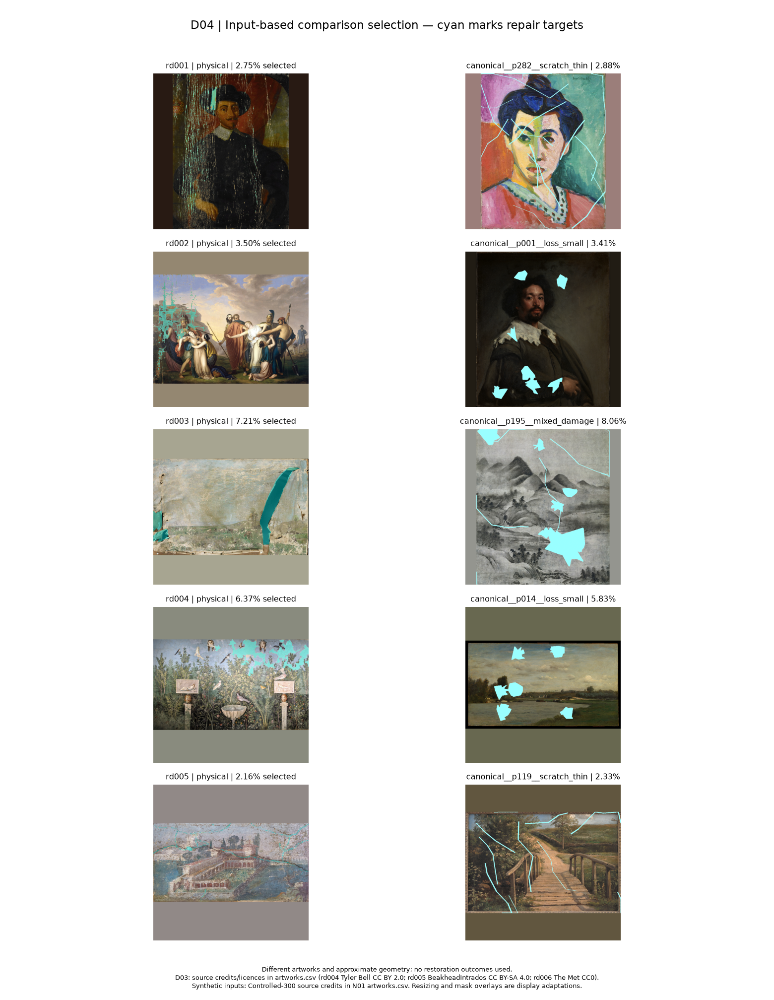

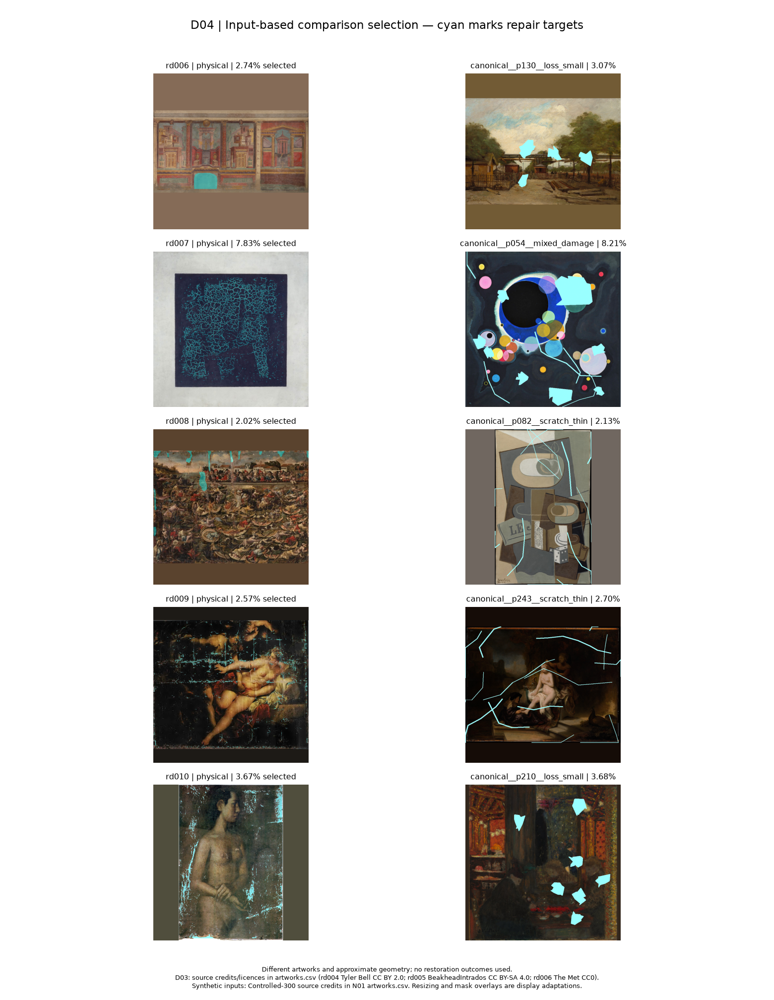

Readiness status: ready_for_method_smoke
Frozen candidates: 70
Existing checkpoint reused: False
Checkpoint: outputs\d04_real_damage_restoration_and_evaluation\work\readiness\readiness_checkpoint.json
Batch 2 elapsed seconds: 82.64


In [7]:
D04_BATCH_2_READY = False

D04_READINESS = rdr.freeze_readiness(D04_READINESS)

D04_VALIDATION = D04_READINESS["validation"]
D04_CANDIDATE_PLAN = D04_READINESS["frozen_plan"]
D04_READINESS_CHECKPOINT = D04_READINESS["readiness_checkpoint"]
D04_READINESS_POLICY = D04_READINESS["readiness_policy"]

D04_INPUTS = D04_READINESS["inputs"]
D04_INPUT_CHECKSUMS = D04_READINESS["input_checksums"]
D04_INVENTORY_RUN = D04_READINESS["inventory"]
D04_OUTPUT_ROOT = D04_READINESS["output_root"]
D04_OUTPUTS = D04_READINESS["outputs"]
D04_PROMPTS = D04_READINESS["prompts"]

display(pd.DataFrame([D04_VALIDATION.summary()]))

display(
    D04_CANDIDATE_PLAN.groupby(
        ["model_id", "candidate_role"],
        sort=False,
    )
    .size()
    .rename("planned_candidates")
    .reset_index()
)

for preview_key in ("preview_first", "preview_second"):
    preview_path = (
        D04_OUTPUT_ROOT
        / D04_READINESS_POLICY["outputs"][preview_key]
    )
    display(NotebookImage(
        filename=str(preview_path),
        width=1050,
    ))

D04_VALIDATION.raise_for_blocking()
D04_BATCH_2_READY = True

print("Readiness status:", D04_READINESS_CHECKPOINT["status"])
print("Frozen candidates:", len(D04_CANDIDATE_PLAN))
print("Existing checkpoint reused:", D04_READINESS["reused"])
print(
    "Checkpoint:",
    D04_READINESS["checkpoint_path"].relative_to(PROJECT_ROOT),
)
print(
    "Batch 2 elapsed seconds:",
    round(perf_counter() - D04_BATCH_2_STARTED, 2),
)

## Batch 3 — OpenCV Telea smoke check and primary restorations

Apply the unchanged OpenCV Telea implementation to the ten physical cases:
radius 3, binary mask threshold 128, CPU execution and 768 × 768 inputs.
No resizing, mask expansion or parameter tuning is introduced.

The smoke check restores rd007 twice to check repeatability and
outside-mask preservation. An additional in-memory empty-mask check
verifies identity behaviour. Smoke outputs are stored separately and
excluded from the ten primary candidates.

Primary restorations retain their frozen candidate identifiers. Each
candidate receives an execution receipt and output checksum. Verified
results can be reused; changed inputs, settings or outputs block reuse.

Validation concerns execution, file integrity and preservation of pixels
outside the repair mask. Inside-mask change describes edit magnitude,
not reconstruction accuracy. These paintings have no clean references.
Visually unconvincing but technically valid restorations are retained.

In [8]:
import importlib
from pathlib import Path

import pandas as pd
from IPython.display import display, Image as NotebookImage
from restoration_eval import real_damage_telea

if not globals().get("D04_BATCH_2_READY", False):
    raise RuntimeError("D04 Batch 2 has not passed in this kernel.")

D04_BATCH_3_READY = False
rdt = importlib.reload(real_damage_telea)

EXPECTED_TELEA_HELPER = (
    PROJECT_ROOT / "src/restoration_eval/real_damage_telea.py"
).resolve()

if Path(rdt.__file__).resolve() != EXPECTED_TELEA_HELPER:
    raise RuntimeError("Telea adapter came from another checkout.")

D04_TELEA_CONFIG_PATH = (
    PROJECT_ROOT / "config/experiments/real_damage_telea.yaml"
)

D04_TELEA = rdt.prepare_telea(
    PROJECT_ROOT,
    D04_TELEA_CONFIG_PATH,
)

display(pd.DataFrame([D04_TELEA["validation"].summary()]))

display(
    D04_TELEA["worklist"][[
        "painting_id",
        "category",
        "candidate_id",
        "configuration_id",
        "mask_threshold",
    ]]
)

print(
    "Inventory run:",
    D04_TELEA["inventory"]["inventory_run_id"],
)
print(
    "Telea radius:",
    D04_TELEA["baseline"]["model"]["inpaint_radius"],
)
print("Frozen primary candidates:", len(D04_TELEA["worklist"]))

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,60,60,0,0,True,[]


,painting_id,category,candidate_id,configuration_id,mask_threshold
0,rd001,portrait_figure,d04_candidate_f3265f30aaf8bb85e3e2c0e8,opencv_telea_r3_threshold_policy_v1,128
1,rd002,portrait_figure,d04_candidate_b69236bca0868725db8477b3,opencv_telea_r3_threshold_policy_v1,128
2,rd003,landscape_natural,d04_candidate_37ce9694e255420d9c9198b3,opencv_telea_r3_threshold_policy_v1,128
3,rd004,landscape_natural,d04_candidate_c9804e1576fcc52b80269130,opencv_telea_r3_threshold_policy_v1,128
4,rd005,architecture_structured,d04_candidate_0a468b792be54c0c8aa3bb69,opencv_telea_r3_threshold_policy_v1,128
5,rd006,architecture_structured,d04_candidate_f7a54270ee9a44f576ba1208,opencv_telea_r3_threshold_policy_v1,128
6,rd007,abstraction_surrealism,d04_candidate_e33b00ef963e8df85cff544f,opencv_telea_r3_threshold_policy_v1,128
7,rd008,abstraction_surrealism,d04_candidate_8acc2d8e46ac539ef10b2563,opencv_telea_r3_threshold_policy_v1,128
8,rd009,high_texture_brushwork,d04_candidate_8baacbe03ea6e2d1544bd837,opencv_telea_r3_threshold_policy_v1,128
9,rd010,high_texture_brushwork,d04_candidate_c64bf594b1bd1425fe9c1038,opencv_telea_r3_threshold_policy_v1,128


Inventory run: inventory_20261115T122836Z_bcc4f94f
Telea radius: 3
Frozen primary candidates: 10


In [9]:
D04_TELEA = rdt.run_smoke(D04_TELEA)

D04_TELEA_SMOKE = pd.DataFrame(
    D04_TELEA["smoke_records"]
)

display(
    D04_TELEA_SMOKE[[
        "painting_id",
        "execution_scope",
        "status",
        "width",
        "height",
        "changed_inside_pixels",
        "changed_outside_pixels",
        "runtime_seconds",
        "restored_sha256",
    ]].round(4)
)

D04_SMOKE_CHECKS = D04_TELEA["validation"].to_dataframe()
display(
    D04_SMOKE_CHECKS.loc[
        D04_SMOKE_CHECKS["validation_stage"].eq(
            "batch_3_telea"
        )
        & D04_SMOKE_CHECKS["check_id"].str.startswith("smoke_"),
        [
            "check_id",
            "check_description",
            "expected",
            "observed",
            "passed",
        ],
    ]
)

D04_TELEA["validation"].raise_for_blocking()

,painting_id,execution_scope,status,width,height,changed_inside_pixels,changed_outside_pixels,runtime_seconds,restored_sha256
0,rd007,smoke_1,completed,768,768,46168,0,0.5947,82d363b4c025af60749f52079fa71d7fad5bd3980caeb5...
1,rd007,smoke_2,completed,768,768,46168,0,0.5877,82d363b4c025af60749f52079fa71d7fad5bd3980caeb5...


,check_id,check_description,expected,observed,passed
60,smoke_repeatability,Two identical-input smoke runs produce identic...,82d363b4c025af60749f52079fa71d7fad5bd3980caeb5...,82d363b4c025af60749f52079fa71d7fad5bd3980caeb5...,True
61,smoke_outside,Both smoke runs preserve every outside-mask pixel,"[0, 0]","[0, 0]",True
62,smoke_shape,Smoke PNG dimensions and RGB mode match the input,True,"[768, 768]",True
63,smoke_zero_identity,Empty-mask technical control preserves all pixels,identity_noop,identity_noop,True


In [10]:
D04_TELEA = rdt.run_candidates(
    D04_TELEA,
    progress=lambda message: print(message, flush=True),
)

D04_TELEA_CANDIDATES = D04_TELEA["records"]

display(
    D04_TELEA_CANDIDATES.reindex(columns=[
        "painting_id",
        "status",
        "runtime_seconds",
        "changed_inside_pixels",
        "changed_outside_pixels",
        "inside_change_fraction",
        "issue",
    ]).round(4)
)

D04_TELEA = rdt.validate_results(D04_TELEA)
D04_VALIDATION = D04_TELEA["validation"]

display(pd.DataFrame([D04_VALIDATION.summary()]))

display(pd.DataFrame([{
    "model": "opencv_telea",
    "completed_primary_candidates": (
        D04_TELEA["summary"]["completed_candidates"]
    ),
    "failed_candidates": (
        D04_TELEA["summary"]["failed_candidates"]
    ),
    "reused_candidates": (
        D04_TELEA["summary"]["reused_candidates"]
    ),
    "recorded_primary_runtime_seconds": round(
        D04_TELEA["summary"]["recorded_case_runtime_seconds"],
        3,
    ),
}]))

D04_CANDIDATES = pd.read_csv(
    D04_OUTPUT_ROOT / D04_CONFIG["outputs"]["candidates"],
    keep_default_na=False,
)

Telea 1/10 | rd001 | completed
Telea 2/10 | rd002 | completed
Telea 3/10 | rd003 | completed
Telea 4/10 | rd004 | completed
Telea 5/10 | rd005 | completed
Telea 6/10 | rd006 | completed
Telea 7/10 | rd007 | completed
Telea 8/10 | rd008 | completed
Telea 9/10 | rd009 | completed
Telea 10/10 | rd010 | completed


,painting_id,status,runtime_seconds,changed_inside_pixels,changed_outside_pixels,inside_change_fraction,issue
0,rd001,completed,0.3248,12121,0,0.9999,
1,rd002,completed,0.3452,14484,0,0.9999,
2,rd003,completed,0.2615,26295,0,0.9998,
3,rd004,completed,0.2512,21871,0,1.0000,
4,rd005,completed,0.1856,6448,0,0.9998,
5,rd006,completed,0.2418,8530,0,0.9998,
6,rd007,completed,0.6184,46168,0,1.0000,
7,rd008,completed,0.2414,8639,0,0.9992,
8,rd009,completed,0.3811,12540,0,1.0000,
9,rd010,completed,0.3095,14411,0,0.9916,


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,95,95,0,0,True,[]


,model,completed_primary_candidates,failed_candidates,reused_candidates,recorded_primary_runtime_seconds
0,opencv_telea,10,0,0,3.16


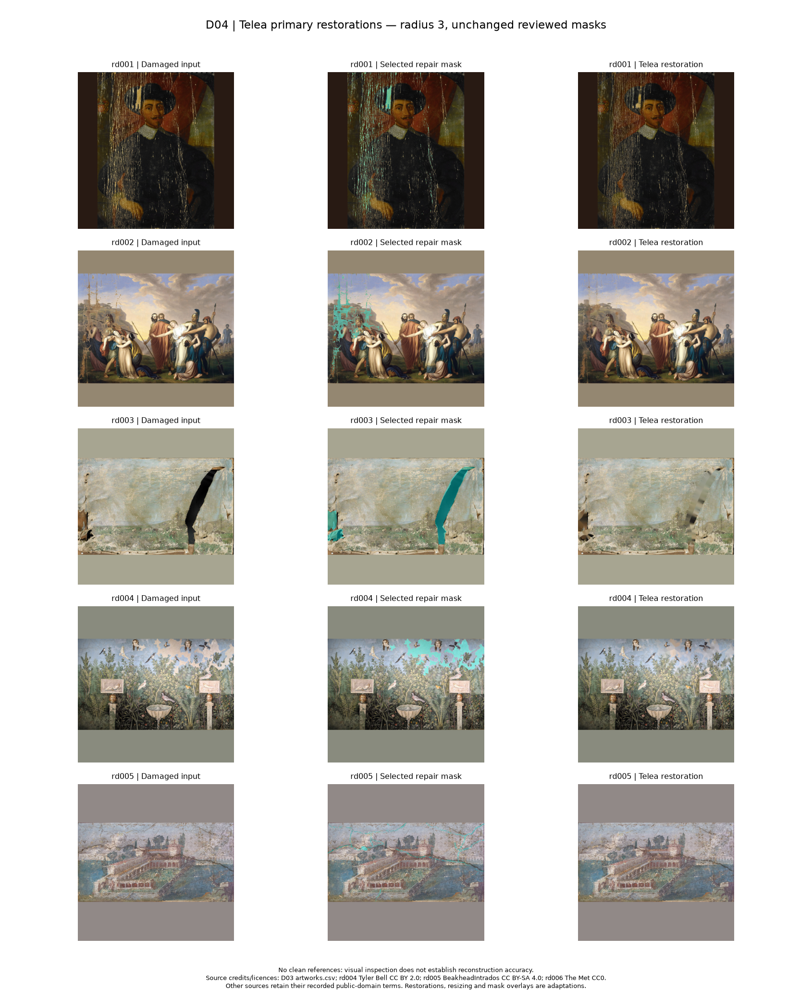

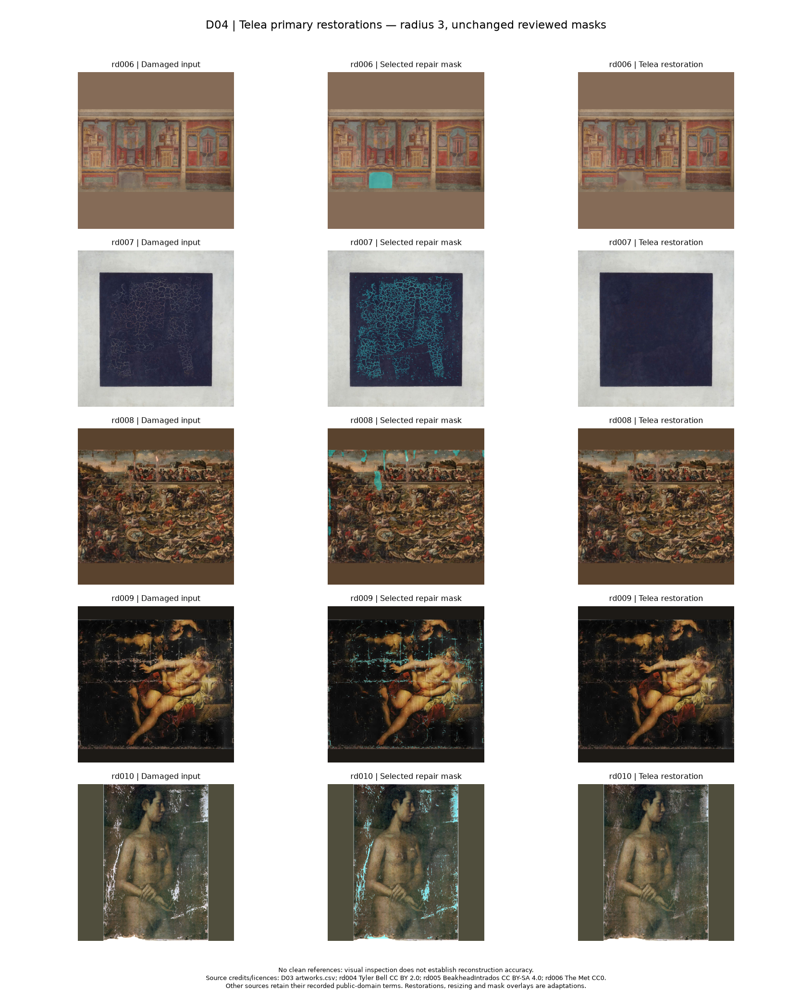

Telea primary restorations: 10 completed.
Validation checks passed: 95
Candidate table: outputs\d04_real_damage_restoration_and_evaluation\data\candidates.csv
Remaining restoration methods: LaMa, HINT and Stable Diffusion.


In [11]:
D04_TELEA_PREVIEW_PATHS = rdt.render_previews(D04_TELEA)

for preview_path in D04_TELEA_PREVIEW_PATHS:
    display(NotebookImage(
        filename=str(preview_path),
        width=1150,
    ))

D04_VALIDATION.raise_for_blocking()
D04_BATCH_3_READY = True

print("Telea primary restorations: 10 completed.")
print(
    "Validation checks passed:",
    D04_VALIDATION.summary()["passed_count"],
)
print(
    "Candidate table:",
    D04_OUTPUTS["candidates"].relative_to(PROJECT_ROOT),
)
print("Remaining restoration methods: LaMa, HINT and Stable Diffusion.")

## Batch 4 — LaMa restoration

This batch applies the unchanged N10 LaMa pipeline to the ten physical-damage
cases. It uses the existing IOPaint implementation and cached checkpoint,
CUDA execution, 768-pixel inputs and the reviewed binary masks. Masked
compositing preserves every pixel outside the selected repair regions.

Two separate smoke runs on rd007 assess repeatability using the original
N10 numerical tolerance. An empty-mask compositor check verifies identity
behaviour. These technical controls are excluded from primary candidate counts.

The ten primary restorations retain their frozen candidate identifiers.
Completed images receive checksum-bound receipts, allowing verified outputs
and interrupted raw inference results to be recovered without repeating
completed inference.

Runtime is recorded for each IOPaint command group, including startup and
checkpointing. It is not an individually measured image runtime.

These photographs have no clean references. Technical validation and visual
inspection do not establish reconstruction accuracy or historical authenticity.

In [12]:
import importlib
from pathlib import Path

import pandas as pd
from IPython.display import display, Image as NotebookImage
from restoration_eval import real_damage_lama

if not globals().get("D04_BATCH_3_READY", False):
    raise RuntimeError("D04 Batch 3 has not passed in this kernel.")

D04_BATCH_4_READY = False
rdl = importlib.reload(real_damage_lama)

EXPECTED_LAMA_HELPER = (
    PROJECT_ROOT / "src/restoration_eval/real_damage_lama.py"
).resolve()

if Path(rdl.__file__).resolve() != EXPECTED_LAMA_HELPER:
    raise RuntimeError("LaMa adapter came from another checkout.")

D04_LAMA_CONFIG_PATH = (
    PROJECT_ROOT / "config/experiments/real_damage_lama.yaml"
)

D04_LAMA = rdl.prepare_lama(
    PROJECT_ROOT,
    D04_LAMA_CONFIG_PATH,
)

display(pd.DataFrame([D04_LAMA["validation"].summary()]))

display(
    D04_LAMA["worklist"][[
        "painting_id",
        "category",
        "candidate_id",
        "configuration_id",
        "mask_threshold",
    ]]
)

display(pd.DataFrame([{
    key: D04_LAMA["environment"][key]
    for key in (
        "iopaint_version",
        "torch_version",
        "effective_device",
        "model_artifact_path",
        "model_artifact_sha256",
    )
}]))

print(
    "Inventory run:",
    D04_LAMA["inventory"]["inventory_run_id"],
)
print("Frozen LaMa primary candidates:", len(D04_LAMA["worklist"]))

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,100,100,0,0,True,[]


,painting_id,category,candidate_id,configuration_id,mask_threshold
0,rd001,portrait_figure,d04_candidate_3a2a28888a88e39493595a8c,lama_iopaint_masked_composite_v1,128
1,rd002,portrait_figure,d04_candidate_cb9527c067fb9660c8a05e06,lama_iopaint_masked_composite_v1,128
2,rd003,landscape_natural,d04_candidate_3086493b08f8139cc7636d80,lama_iopaint_masked_composite_v1,128
3,rd004,landscape_natural,d04_candidate_3b7c14a15a8c6120344c3a25,lama_iopaint_masked_composite_v1,128
4,rd005,architecture_structured,d04_candidate_0e15e622a7c66ff4a685ab8d,lama_iopaint_masked_composite_v1,128
5,rd006,architecture_structured,d04_candidate_db9636fd0c7688ed57cdb089,lama_iopaint_masked_composite_v1,128
6,rd007,abstraction_surrealism,d04_candidate_939bf2fadfdf510bcec194f1,lama_iopaint_masked_composite_v1,128
7,rd008,abstraction_surrealism,d04_candidate_959f4df0ede2320da1ae5260,lama_iopaint_masked_composite_v1,128
8,rd009,high_texture_brushwork,d04_candidate_0b69e0b537f4be1ade5d5192,lama_iopaint_masked_composite_v1,128
9,rd010,high_texture_brushwork,d04_candidate_7a36e6cb0fb4fb633953b4ff,lama_iopaint_masked_composite_v1,128


,iopaint_version,torch_version,effective_device,model_artifact_path,model_artifact_sha256
0,1.6.0,2.5.1+cu121,cuda,C:\Users\rahul\.cache\torch\hub\checkpoints\bi...,344c77bbcb158f17dd143070d1e789f38a66c04202311a...


Inventory run: inventory_20261115T125414Z_97019d0b
Frozen LaMa primary candidates: 10


In [13]:
D04_LAMA = rdl.run_smoke(D04_LAMA)

display(pd.DataFrame([
    D04_LAMA["smoke_summary"]["repeatability"]
]))

display(pd.DataFrame([{
    "painting_id": D04_LAMA["smoke_summary"]["painting_id"],
    "repeat_count": D04_LAMA["smoke_summary"]["repeat_count"],
    "zero_mask_identity": (
        D04_LAMA["smoke_summary"]["zero_mask_identity"]
    ),
    "smoke_passed": D04_LAMA["smoke_passed"],
}]))

display(pd.DataFrame([D04_LAMA["validation"].summary()]))

LaMa smoke_1 | command elapsed 15s
LaMa smoke_1 | command elapsed 30s
LaMa smoke_1 1/1 | rd007 | completed
LaMa smoke_1 | command elapsed 45s
LaMa smoke_2 | command elapsed 15s
LaMa smoke_2 1/1 | rd007 | completed


,maximum_absolute_difference,mean_absolute_difference,different_pixel_fraction,sha256_equal,measurement_region,passed
0,0,0.0,0.0,True,full_768_canvas_as_in_N10,True


,painting_id,repeat_count,zero_mask_identity,smoke_passed
0,rd007,2,True,True


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,103,103,0,0,True,[]


In [14]:
D04_LAMA = rdl.run_candidates(D04_LAMA)
D04_LAMA = rdl.validate_results(D04_LAMA)

D04_VALIDATION = D04_LAMA["validation"]

display(
    D04_LAMA["records"][[
        "painting_id",
        "candidate_id",
        "status",
        "width",
        "height",
        "mask_pixels",
        "changed_inside_pixels",
        "changed_outside_pixels",
        "inside_change_fraction",
    ]]
)

display(pd.DataFrame([{
    key: D04_LAMA["summary"][key]
    for key in (
        "completed_candidates",
        "failed_candidates",
        "reused_candidates",
        "recorded_command_runtime_seconds",
        "command_groups",
        "command_groups_missing_runtime",
        "individual_case_runtime_available",
    )
}]))

D04_CANDIDATES = pd.read_csv(
    D04_OUTPUTS["candidates"],
    keep_default_na=False,
    float_precision="round_trip",
)

display(
    D04_CANDIDATES.groupby(
        ["model_id", "status"],
        dropna=False,
    ).size().rename("candidate_count").reset_index()
)

display(pd.DataFrame([D04_VALIDATION.summary()]))

LaMa primary | command elapsed 15s
LaMa primary 1/10 | rd001 | completed
LaMa primary | command elapsed 31s
LaMa primary 2/10 | rd002 | completed
LaMa primary 3/10 | rd003 | completed
LaMa primary 4/10 | rd004 | completed
LaMa primary 5/10 | rd005 | completed
LaMa primary 6/10 | rd006 | completed
LaMa primary 7/10 | rd007 | completed
LaMa primary 8/10 | rd008 | completed
LaMa primary 9/10 | rd009 | completed
LaMa primary 10/10 | rd010 | completed
LaMa primary | command elapsed 46s


,painting_id,candidate_id,status,width,height,mask_pixels,changed_inside_pixels,changed_outside_pixels,inside_change_fraction
0,rd001,d04_candidate_3a2a28888a88e39493595a8c,completed,768,768,12122,12122,0,1.000000
1,rd002,d04_candidate_cb9527c067fb9660c8a05e06,completed,768,768,14486,14486,0,1.000000
2,rd003,d04_candidate_3086493b08f8139cc7636d80,completed,768,768,26300,26299,0,0.999962
3,rd004,d04_candidate_3b7c14a15a8c6120344c3a25,completed,768,768,21872,21870,0,0.999909
4,rd005,d04_candidate_0e15e622a7c66ff4a685ab8d,completed,768,768,6449,6449,0,1.000000
5,rd006,d04_candidate_db9636fd0c7688ed57cdb089,completed,768,768,8532,8528,0,0.999531
6,rd007,d04_candidate_939bf2fadfdf510bcec194f1,completed,768,768,46168,46156,0,0.999740
7,rd008,d04_candidate_959f4df0ede2320da1ae5260,completed,768,768,8646,8639,0,0.999190
8,rd009,d04_candidate_0b69e0b537f4be1ade5d5192,completed,768,768,12540,12538,0,0.999841
9,rd010,d04_candidate_7a36e6cb0fb4fb633953b4ff,completed,768,768,14533,14533,0,1.000000


,completed_candidates,failed_candidates,reused_candidates,recorded_command_runtime_seconds,command_groups,command_groups_missing_runtime,individual_case_runtime_available
0,10,0,0,47.026742,1,0,False


,model_id,status,candidate_count
0,lama,completed,10
1,opencv_telea,completed,10


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,134,134,0,0,True,[]


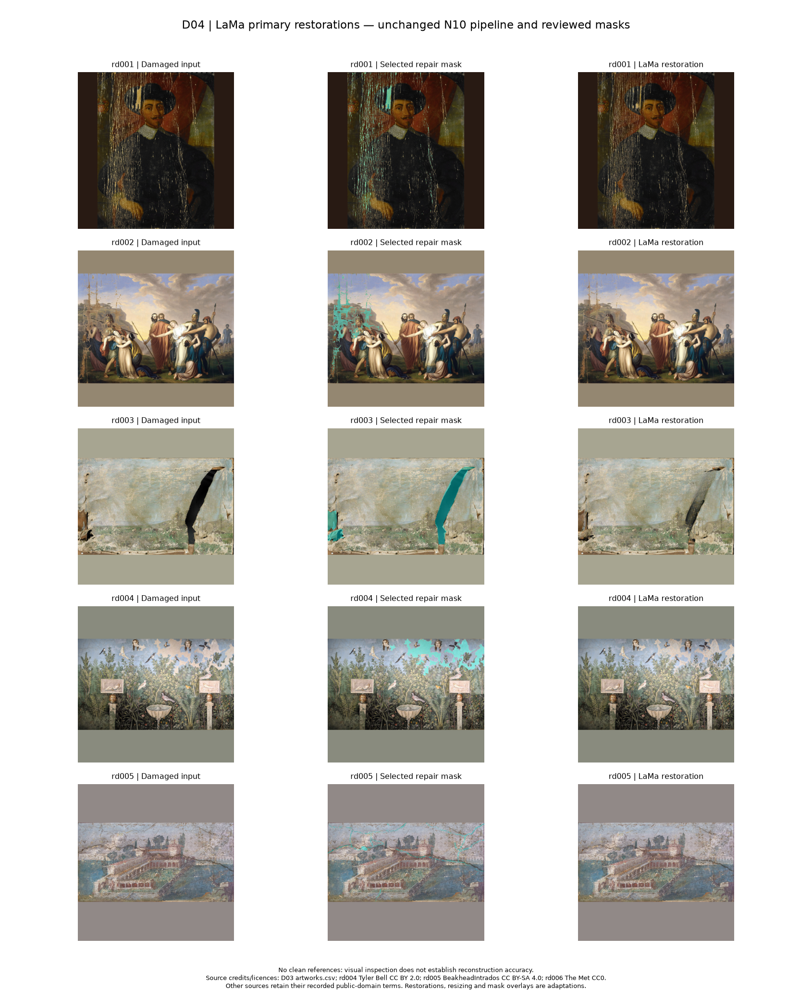

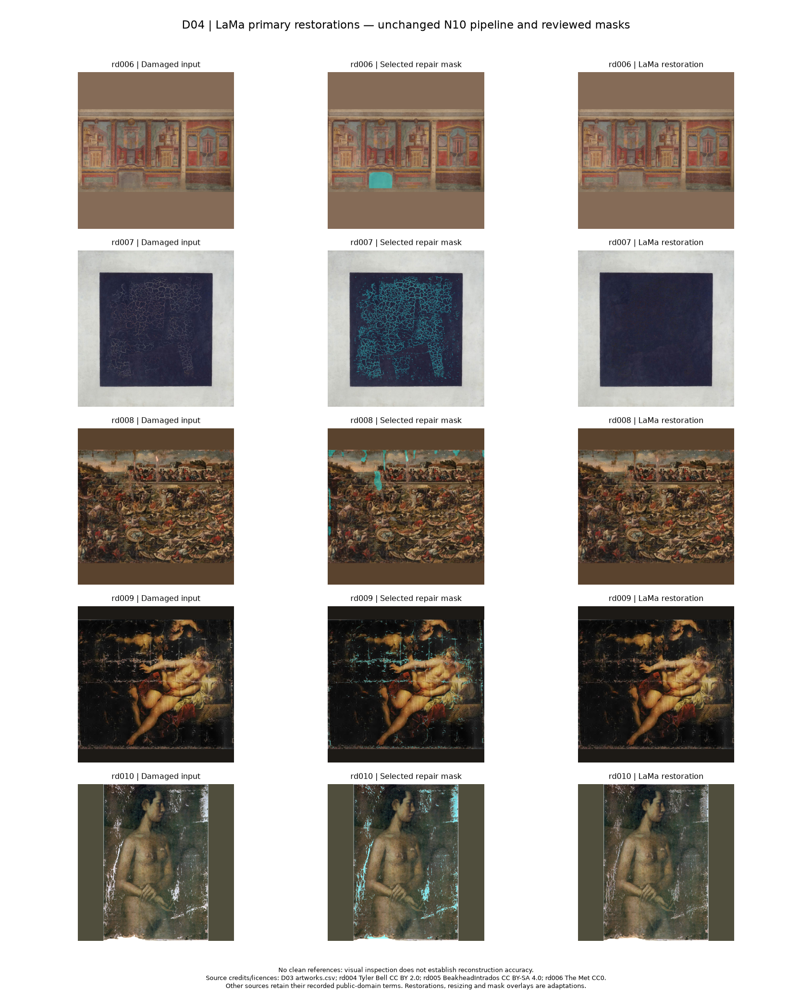

LaMa primary restorations: 10 completed.
Validation checks passed: 134
Candidate table: outputs\d04_real_damage_restoration_and_evaluation\data\candidates.csv


In [15]:
D04_LAMA_PREVIEW_PATHS = rdl.render_previews(D04_LAMA)

for preview_path in D04_LAMA_PREVIEW_PATHS:
    display(NotebookImage(
        filename=str(preview_path),
        width=1150,
    ))

D04_VALIDATION.raise_for_blocking()
D04_BATCH_4_READY = True

print("LaMa primary restorations: 10 completed.")
print(
    "Validation checks passed:",
    D04_VALIDATION.summary()["passed_count"],
)
print(
    "Candidate table:",
    D04_OUTPUTS["candidates"].relative_to(PROJECT_ROOT),
)

## Batch 5 — HINT restoration

This batch applies the unchanged N12A HINT production worker to the ten
physical-damage cases. It uses the pinned Places2 checkpoint, seed 2026,
CUDA float32 execution, native 768-pixel inference and exact masked
compositing. Pixels outside the reviewed repair masks are preserved.

Two smoke restorations of rd007 must produce identical PNG hashes.
An empty-mask compositor control verifies identity behaviour. The model-load
audit is compared with the executed N12A profile: all 973 generator keys
matched, zero missing keys and 153 extra checkpoint keys.

Progress and worker checkpoints are saved after each case. Verified results
can be recovered after interruption, while failed model attempts are retained
without automatic retries. Smoke candidates are excluded from primary counts.

Worker case-call timings exclude model loading. Separate command-group
timings include startup and checkpointing.

These photographs have no clean references. Technical checks and visual
inspection do not establish reconstruction accuracy or historical authenticity.

In [16]:
import importlib
from pathlib import Path

import pandas as pd
from IPython.display import display, Image as NotebookImage
from restoration_eval import real_damage_hint

if not globals().get("D04_BATCH_4_READY", False):
    raise RuntimeError("D04 Batch 4 has not passed in this kernel.")

D04_BATCH_5_READY = False
rdh = importlib.reload(real_damage_hint)

EXPECTED_HINT_HELPER = (
    PROJECT_ROOT / "src/restoration_eval/real_damage_hint.py"
).resolve()

if Path(rdh.__file__).resolve() != EXPECTED_HINT_HELPER:
    raise RuntimeError("HINT adapter came from another checkout.")

D04_HINT_CONFIG_PATH = (
    PROJECT_ROOT / "config/experiments/real_damage_hint.yaml"
)

D04_HINT = rdh.prepare_hint(
    PROJECT_ROOT,
    D04_HINT_CONFIG_PATH,
)

display(pd.DataFrame([D04_HINT["validation"].summary()]))

display(
    D04_HINT["worklist"][[
        "painting_id",
        "category",
        "candidate_id",
        "configuration_id",
        "seed",
        "mask_threshold",
    ]]
)

display(pd.DataFrame([{
    key: D04_HINT["asset"][key]
    for key in (
        "repository_path",
        "actual_repository_revision",
        "checkpoint_path",
        "checkpoint_sha256",
    )
}]))

print(
    "Inventory run:",
    D04_HINT["inventory"]["inventory_run_id"],
)
print("Frozen HINT primary candidates:", len(D04_HINT["worklist"]))
print("Inference device:", D04_HINT["baseline"]["model"]["requested_device"])

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,140,140,0,0,True,[]


,painting_id,category,candidate_id,configuration_id,seed,mask_threshold
0,rd001,portrait_figure,d04_candidate_18ae7a0bf438571076518564,hint_places2_native_768_exact_composite_v1,2026,128
1,rd002,portrait_figure,d04_candidate_f88e434d80886d22124c0091,hint_places2_native_768_exact_composite_v1,2026,128
2,rd003,landscape_natural,d04_candidate_d4ae9ecb4b0c33ac963a7449,hint_places2_native_768_exact_composite_v1,2026,128
3,rd004,landscape_natural,d04_candidate_dd005ba2b6eb595bc4d1e04d,hint_places2_native_768_exact_composite_v1,2026,128
4,rd005,architecture_structured,d04_candidate_2f784c8076677e6cd45f2e7a,hint_places2_native_768_exact_composite_v1,2026,128
5,rd006,architecture_structured,d04_candidate_527f9d072e0b1832a5618f7b,hint_places2_native_768_exact_composite_v1,2026,128
6,rd007,abstraction_surrealism,d04_candidate_cf6bf4991a17f02aefc5a1c6,hint_places2_native_768_exact_composite_v1,2026,128
7,rd008,abstraction_surrealism,d04_candidate_dacece48eff326a523d9d719,hint_places2_native_768_exact_composite_v1,2026,128
8,rd009,high_texture_brushwork,d04_candidate_0a14967aa2726130e3496187,hint_places2_native_768_exact_composite_v1,2026,128
9,rd010,high_texture_brushwork,d04_candidate_dc215f0daf889b324c76c6de,hint_places2_native_768_exact_composite_v1,2026,128


,repository_path,actual_repository_revision,checkpoint_path,checkpoint_sha256
0,D:\Models\HINT,15e867d8c8689b9d5050383fc3884537ae876145,D:\Models\HINT\checkpoints\places2\InpaintingM...,f7c78feac68aa06ff10d6efbb2f8e2cc040720d2ce5ebb...


Inventory run: inventory_20261115T131846Z_8228f7fb
Frozen HINT primary candidates: 10
Inference device: cuda


In [17]:
D04_HINT = rdh.run_smoke(D04_HINT)

display(pd.DataFrame([{
    "painting_id": D04_HINT["smoke_summary"]["painting_id"],
    "repeat_count": D04_HINT["smoke_summary"]["repeat_count"],
    "sha256_equal": D04_HINT["smoke_summary"]["sha256_equal"],
    "zero_mask_identity": (
        D04_HINT["smoke_summary"]["zero_mask_identity"]
    ),
    "smoke_passed": D04_HINT["smoke_passed"],
}]))

display(pd.DataFrame(
    D04_HINT["smoke_summary"]["model_load_audits"]
))

display(pd.DataFrame([D04_HINT["validation"].summary()]))

HINT smoke | worker elapsed 15s
HINT smoke | worker elapsed 30s
HINT smoke | worker elapsed 45s
HINT smoke | rd007 | completed
HINT smoke | rd007 | completed
HINT smoke | worker elapsed 61s


,painting_id,repeat_count,sha256_equal,zero_mask_identity,smoke_passed
0,rd007,2,True,True,True


,model_load_seconds,matched_state_keys,model_state_key_count,missing_state_keys,unexpected_state_keys
0,2.534,973,973,0,153


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,144,144,0,0,True,[]


In [18]:
D04_HINT = rdh.run_candidates(D04_HINT)
D04_HINT = rdh.validate_results(D04_HINT)

D04_VALIDATION = D04_HINT["validation"]

display(
    D04_HINT["records"][[
        "painting_id",
        "candidate_id",
        "status",
        "width",
        "height",
        "mask_pixels",
        "changed_inside_pixels",
        "changed_outside_pixels",
        "inside_change_fraction",
        "inference_seconds",
        "runtime_seconds",
    ]]
)

display(pd.DataFrame([{
    key: D04_HINT["summary"][key]
    for key in (
        "completed_candidates",
        "failed_candidates",
        "reused_candidates",
        "recorded_case_runtime_seconds",
        "recorded_command_runtime_seconds",
        "command_groups",
        "command_groups_missing_runtime",
    )
}]))

D04_CANDIDATES = pd.read_csv(
    D04_OUTPUTS["candidates"],
    keep_default_na=False,
    float_precision="round_trip",
)

display(
    D04_CANDIDATES.groupby(
        ["model_id", "status"],
        dropna=False,
    ).size().rename("candidate_count").reset_index()
)

display(pd.DataFrame([D04_VALIDATION.summary()]))

HINT primary | worker elapsed 15s
HINT primary | worker elapsed 30s
HINT primary | rd001 | completed
HINT primary | rd002 | completed
HINT primary | worker elapsed 46s
HINT primary | rd003 | completed
HINT primary | rd004 | completed
HINT primary | rd005 | completed
HINT primary | worker elapsed 61s
HINT primary | rd006 | completed
HINT primary | rd007 | completed
HINT primary | worker elapsed 77s
HINT primary | rd008 | completed
HINT primary | rd009 | completed
HINT primary | worker elapsed 92s
HINT primary | rd010 | completed


,painting_id,candidate_id,status,width,height,mask_pixels,changed_inside_pixels,changed_outside_pixels,inside_change_fraction,inference_seconds,runtime_seconds
0,rd001,d04_candidate_18ae7a0bf438571076518564,completed,768,768,12122,12122,0,1.000000,14.701,15.053
1,rd002,d04_candidate_f88e434d80886d22124c0091,completed,768,768,14486,14481,0,0.999655,6.171,6.688
2,rd003,d04_candidate_d4ae9ecb4b0c33ac963a7449,completed,768,768,26300,26300,0,1.000000,6.412,6.708
3,rd004,d04_candidate_dd005ba2b6eb595bc4d1e04d,completed,768,768,21872,21870,0,0.999909,6.144,6.394
4,rd005,d04_candidate_2f784c8076677e6cd45f2e7a,completed,768,768,6449,6448,0,0.999845,5.945,6.641
5,rd006,d04_candidate_527f9d072e0b1832a5618f7b,completed,768,768,8532,8532,0,1.000000,6.361,6.685
6,rd007,d04_candidate_cf6bf4991a17f02aefc5a1c6,completed,768,768,46168,46111,0,0.998765,6.128,6.673
7,rd008,d04_candidate_dacece48eff326a523d9d719,completed,768,768,8646,8641,0,0.999422,6.330,6.652
8,rd009,d04_candidate_0a14967aa2726130e3496187,completed,768,768,12540,12538,0,0.999841,6.434,6.878
9,rd010,d04_candidate_dc215f0daf889b324c76c6de,completed,768,768,14533,14369,0,0.988715,6.657,6.895


,completed_candidates,failed_candidates,reused_candidates,recorded_case_runtime_seconds,recorded_command_runtime_seconds,command_groups,command_groups_missing_runtime
0,10,0,0,75.267,97.842321,1,0


,model_id,status,candidate_count
0,hint_places2,completed,10
1,lama,completed,10
2,opencv_telea,completed,10


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,175,175,0,0,True,[]


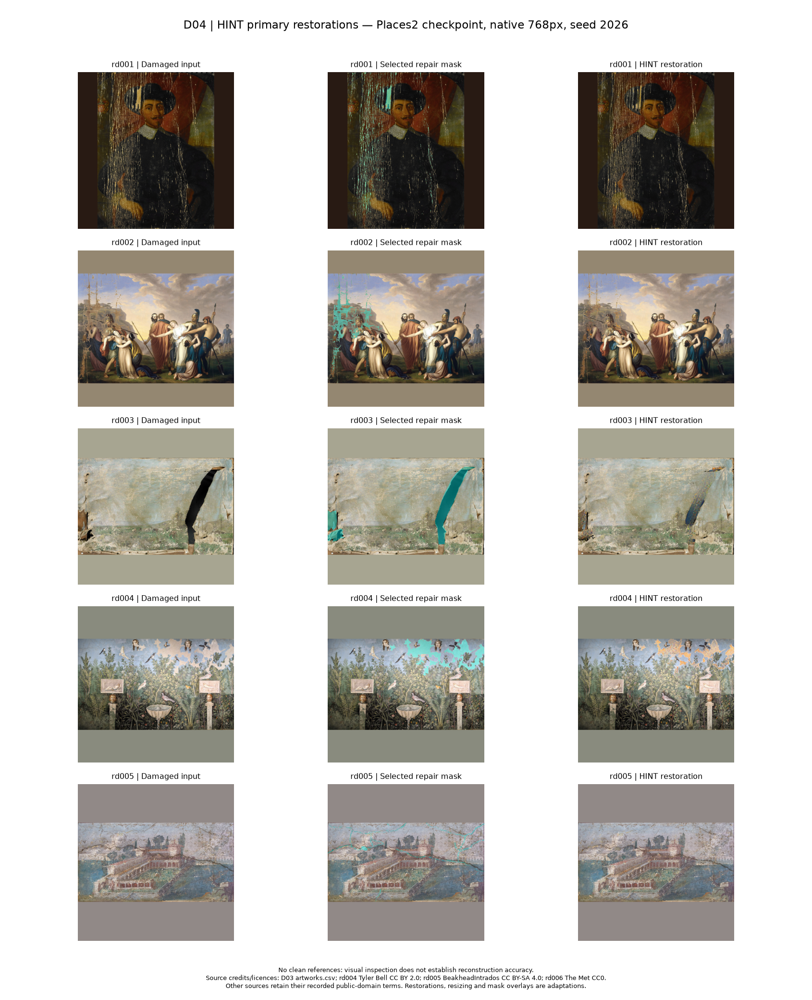

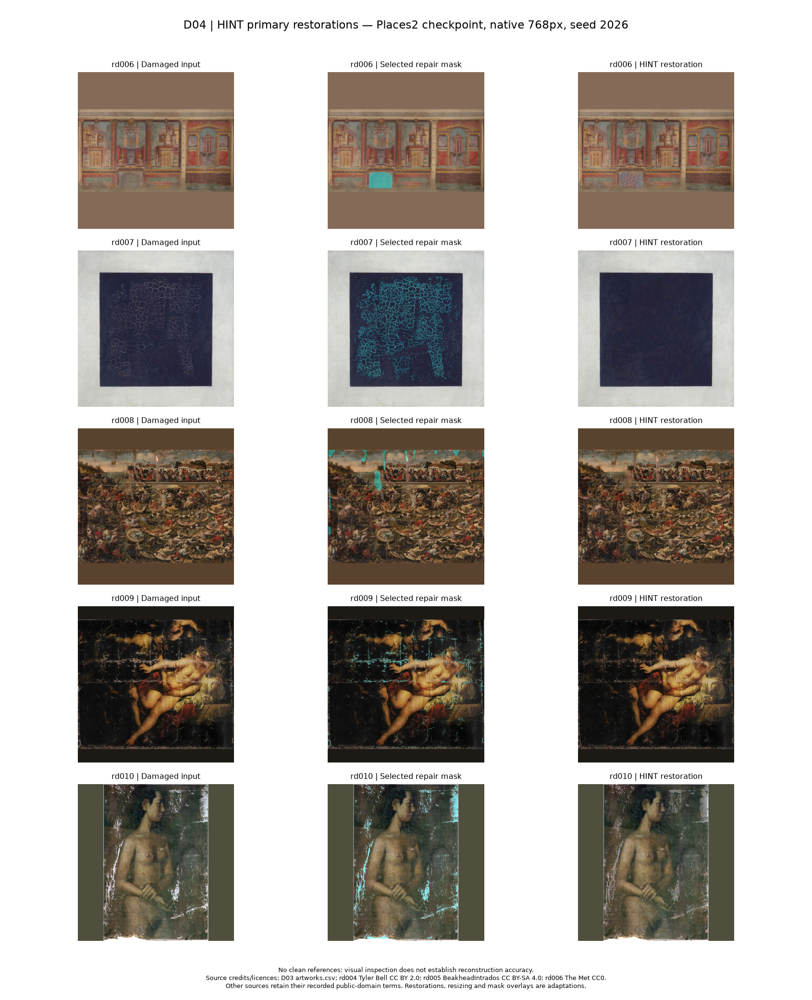

HINT primary restorations: 10 completed.
Validation checks passed: 175
Candidate table: outputs\d04_real_damage_restoration_and_evaluation\data\candidates.csv


In [19]:
D04_HINT_PREVIEW_PATHS = rdh.render_previews(D04_HINT)

for preview_path in D04_HINT_PREVIEW_PATHS:
    display(NotebookImage(
        filename=str(preview_path),
        width=1150,
    ))

D04_VALIDATION.raise_for_blocking()
D04_BATCH_5_READY = True

print("HINT primary restorations: 10 completed.")
print(
    "Validation checks passed:",
    D04_VALIDATION.summary()["passed_count"],
)
print(
    "Candidate table:",
    D04_OUTPUTS["candidates"].relative_to(PROJECT_ROOT),
)

## Batch 6 — Stable Diffusion primary restoration

This batch applies the unchanged N11 Stable Diffusion 1.5 inpainting
pipeline to the ten physical-damage cases. Each painting uses its approved
targeted prompt from the frozen Batch 2 plan. The negative prompt remains
unchanged, and prompts are not adjusted after inspecting results.

Generation uses the pinned checkpoint, DDIM scheduler, 30 inference steps,
guidance scale 7.5, strength 1.0, CUDA float16 and attention slicing.
Inference takes place at 512 pixels. The generated image is resized and
composited onto the 768-pixel input, preserving every pixel outside the
reviewed repair mask.

Three technical smoke candidates for rd007 use seeds 2026, 2026 and 2027.
Repeated-seed outputs must meet the original N11 repeatability tolerances.
The alternate seed checks sensitivity to the random seed. Outside-mask
preservation and an empty-mask compositor control are also checked.
Smoke candidates are excluded from the primary candidate table.

The ten primary restorations use seed 2026. Progress is checkpointed after
each painting, and verified results can be resumed. The baseline permits
one retry using the exact same seed. Failed receipts are retained rather
than repeatedly retried.

The additional seeds belong to Batch 7. These photographs have no clean
references, so technical checks and visual inspection do not establish
reconstruction accuracy or historical authenticity.

In [20]:
import importlib
from pathlib import Path

import pandas as pd
from IPython.display import display, Image as NotebookImage
from restoration_eval import real_damage_sd

if not globals().get("D04_BATCH_5_READY", False):
    raise RuntimeError("D04 Batch 5 has not passed in this kernel.")

D04_BATCH_6_READY = False
rds = importlib.reload(real_damage_sd)

EXPECTED_SD_HELPER = (
    PROJECT_ROOT / "src/restoration_eval/real_damage_sd.py"
).resolve()

if Path(rds.__file__).resolve() != EXPECTED_SD_HELPER:
    raise RuntimeError("SD adapter came from another checkout.")

if "D04_SD" in globals():
    rds.release_pipeline(D04_SD)

D04_SD_CONFIG_PATH = (
    PROJECT_ROOT / "config/experiments/real_damage_sd.yaml"
)

D04_SD = rds.prepare_sd(
    PROJECT_ROOT,
    D04_SD_CONFIG_PATH,
)

display(pd.DataFrame([D04_SD["validation"].summary()]))

display(
    D04_SD["worklist"][[
        "painting_id",
        "category",
        "prompt_id",
        "seed",
        "num_inference_steps",
        "guidance_scale",
        "strength",
        "inference_width",
        "output_width",
    ]]
)

display(D04_SD["tokenizer_audit"])

print("Inventory run:", D04_SD["inventory"]["inventory_run_id"])
print("Primary SD candidates:", len(D04_SD["worklist"]))
print("Pinned model revision:", D04_SD["asset"]["revision"])

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,181,181,0,0,True,[]


,painting_id,category,prompt_id,seed,num_inference_steps,guidance_scale,strength,inference_width,output_width
0,rd001,portrait_figure,d04_targeted_rd001_v1,2026,30,7.5,1.0,512,768
1,rd002,portrait_figure,d04_targeted_rd002_v1,2026,30,7.5,1.0,512,768
2,rd003,landscape_natural,d04_targeted_rd003_v1,2026,30,7.5,1.0,512,768
3,rd004,landscape_natural,d04_targeted_rd004_v1,2026,30,7.5,1.0,512,768
4,rd005,architecture_structured,d04_targeted_rd005_v1,2026,30,7.5,1.0,512,768
5,rd006,architecture_structured,d04_targeted_rd006_v1,2026,30,7.5,1.0,512,768
6,rd007,abstraction_surrealism,d04_targeted_rd007_v1,2026,30,7.5,1.0,512,768
7,rd008,abstraction_surrealism,d04_targeted_rd008_v1,2026,30,7.5,1.0,512,768
8,rd009,high_texture_brushwork,d04_targeted_rd009_v1,2026,30,7.5,1.0,512,768
9,rd010,high_texture_brushwork,d04_targeted_rd010_v1,2026,30,7.5,1.0,512,768


,painting_id,prompt_id,kind,tokens,maximum_tokens,fits,truncation_used
0,rd001,d04_targeted_rd001_v1,positive,49,77,True,False
1,rd002,d04_targeted_rd002_v1,positive,50,77,True,False
2,rd003,d04_targeted_rd003_v1,positive,52,77,True,False
3,rd004,d04_targeted_rd004_v1,positive,46,77,True,False
4,rd005,d04_targeted_rd005_v1,positive,51,77,True,False
5,rd006,d04_targeted_rd006_v1,positive,51,77,True,False
6,rd007,d04_targeted_rd007_v1,positive,47,77,True,False
7,rd008,d04_targeted_rd008_v1,positive,54,77,True,False
8,rd009,d04_targeted_rd009_v1,positive,53,77,True,False
9,rd010,d04_targeted_rd010_v1,positive,57,77,True,False


Inventory run: inventory_20261115T134405Z_c20ad9e6
Primary SD candidates: 10
Pinned model revision: 8a4288a76071f7280aedbdb3253bdb9e9d5d84bb


In [21]:
D04_SD = rds.run_smoke(D04_SD)

display(pd.DataFrame([
    {
        "comparison": "fixed_seed_repeat",
        **D04_SD["smoke_summary"]["fixed_repeat"],
    },
    {
        "comparison": "alternate_seed",
        **D04_SD["smoke_summary"]["alternate_seed"],
    },
]))

display(pd.DataFrame([{
    "painting_id": D04_SD["smoke_summary"]["painting_id"],
    "smoke_seeds": D04_SD["smoke_summary"]["seeds"],
    "zero_mask_identity": (
        D04_SD["smoke_summary"]["zero_mask_identity"]
    ),
    "smoke_passed": D04_SD["smoke_passed"],
    "primary_candidates_from_smoke": (
        D04_SD["smoke_summary"]["primary_candidate_count"]
    ),
}]))

display(pd.DataFrame([D04_SD["validation"].summary()]))

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]D:\Masters\FH\Thesis\painting-restoration-eval\.venv\Lib\site-packages\diffusers\models\modeling_utils.py:110: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub fo

SD smoke 1/3: completed (reused=False)


100%|██████████| 30/30 [00:13<00:00,  2.16it/s]


SD smoke 2/3: completed (reused=False)


100%|██████████| 30/30 [00:13<00:00,  2.18it/s]


SD smoke 3/3: completed (reused=False)


,comparison,maximum_absolute_difference,mean_absolute_difference,different_pixel_fraction,inside_different_pixels,outside_different_pixels
0,fixed_seed_repeat,0,0.000000,0.000000,0,0
1,alternate_seed,200,2.342347,0.078239,46147,0


,painting_id,smoke_seeds,zero_mask_identity,smoke_passed,primary_candidates_from_smoke
0,rd007,"[2026, 2026, 2027]",True,True,0


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,185,185,0,0,True,[]


In [22]:
D04_SD = rds.run_candidates(D04_SD)
D04_SD = rds.validate_results(D04_SD)

D04_VALIDATION = D04_SD["validation"]

display(
    D04_SD["records"][[
        "painting_id",
        "candidate_id",
        "prompt_id",
        "seed",
        "status",
        "width",
        "height",
        "mask_pixels",
        "changed_inside_pixels",
        "changed_outside_pixels",
        "inside_change_fraction",
        "retry_count",
        "runtime_seconds",
    ]]
)

display(pd.DataFrame([{
    key: D04_SD["summary"][key]
    for key in (
        "completed_candidates",
        "failed_candidates",
        "reused_candidates",
        "recorded_case_runtime_seconds",
        "runtime_scope",
    )
}]))

D04_CANDIDATES = pd.read_csv(
    D04_OUTPUTS["candidates"],
    keep_default_na=False,
    float_precision="round_trip",
)

display(
    D04_CANDIDATES.groupby(
        ["model_id", "candidate_role", "status"],
        dropna=False,
    ).size().rename("candidate_count").reset_index()
)

display(pd.DataFrame([D04_VALIDATION.summary()]))

100%|██████████| 30/30 [00:13<00:00,  2.22it/s]


SD primary 1/10 | rd001 | seed 2026 | completed | reused=False


100%|██████████| 30/30 [00:13<00:00,  2.24it/s]


SD primary 2/10 | rd002 | seed 2026 | completed | reused=False


100%|██████████| 30/30 [00:13<00:00,  2.19it/s]


SD primary 3/10 | rd003 | seed 2026 | completed | reused=False


... (14 outputs left out)

,painting_id,candidate_id,prompt_id,seed,status,width,height,mask_pixels,changed_inside_pixels,changed_outside_pixels,inside_change_fraction,retry_count,runtime_seconds
0,rd001,d04_candidate_abaccf2dc83f98ea08d0a74b,d04_targeted_rd001_v1,2026,completed,768,768,12122,12122,0,1.000000,0,14.193217
1,rd002,d04_candidate_f3d8afda0c97616494ca41b2,d04_targeted_rd002_v1,2026,completed,768,768,14486,14486,0,1.000000,0,14.283658
2,rd003,d04_candidate_a9d8544bc49b0efcdaebc360,d04_targeted_rd003_v1,2026,completed,768,768,26300,26300,0,1.000000,0,14.445668
3,rd004,d04_candidate_0fbcd851084ed6a29a2ba31c,d04_targeted_rd004_v1,2026,completed,768,768,21872,21872,0,1.000000,0,14.893810
4,rd005,d04_candidate_121f27649713c65e0eecf460,d04_targeted_rd005_v1,2026,completed,768,768,6449,6448,0,0.999845,0,14.476903
5,rd006,d04_candidate_012f317d8cc87b825713c854,d04_targeted_rd006_v1,2026,completed,768,768,8532,8532,0,1.000000,0,14.766656
6,rd007,d04_candidate_3c976b9bcacb215da9fd6b22,d04_targeted_rd007_v1,2026,completed,768,768,46168,46168,0,1.000000,0,15.248150
7,rd008,d04_candidate_4aa283ef1bc2d1458cff073c,d04_targeted_rd008_v1,2026,completed,768,768,8646,8645,0,0.999884,0,14.972742
8,rd009,d04_candidate_1b201e2764f869ad91fb5cb3,d04_targeted_rd009_v1,2026,completed,768,768,12540,12540,0,1.000000,0,14.061304
9,rd010,d04_candidate_3759a691a6a3326962510838,d04_targeted_rd010_v1,2026,completed,768,768,14533,14533,0,1.000000,0,13.622712


,completed_candidates,failed_candidates,reused_candidates,recorded_case_runtime_seconds,runtime_scope
0,10,0,0,144.964821,original_case_calls_include_baseline_retry_exc...


,model_id,candidate_role,status,candidate_count
0,hint_places2,primary,completed,10
1,lama,primary,completed,10
2,opencv_telea,primary,completed,10
3,stable_diffusion_inpainting,primary,completed,10


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,216,216,0,0,True,[]


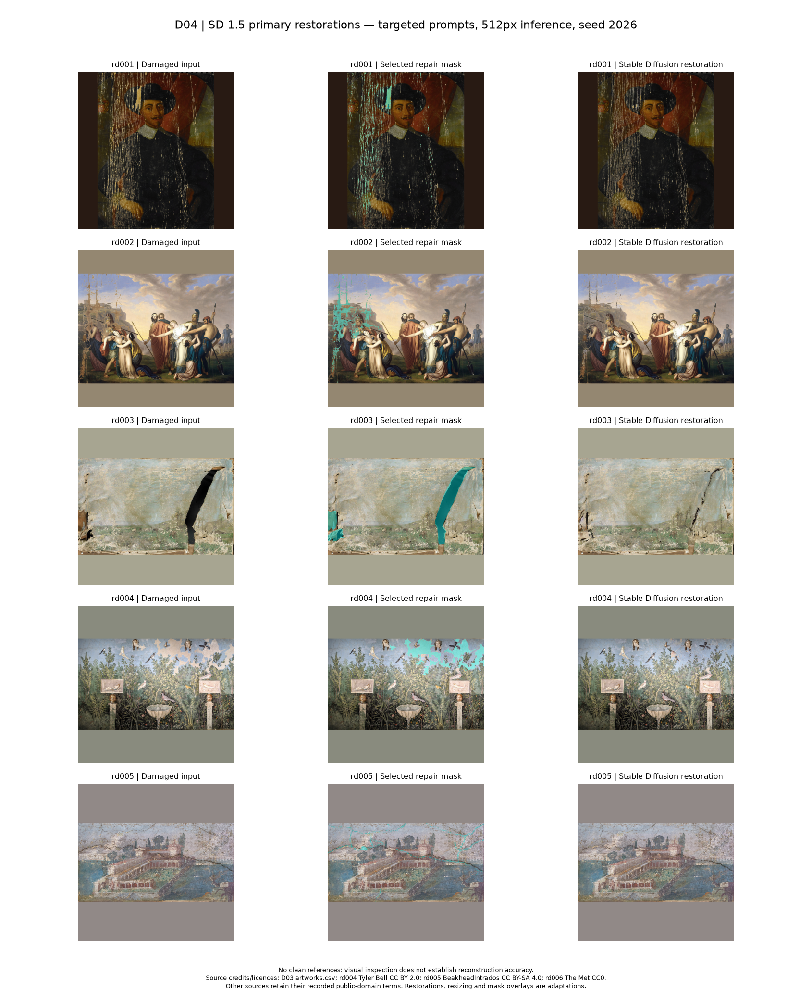

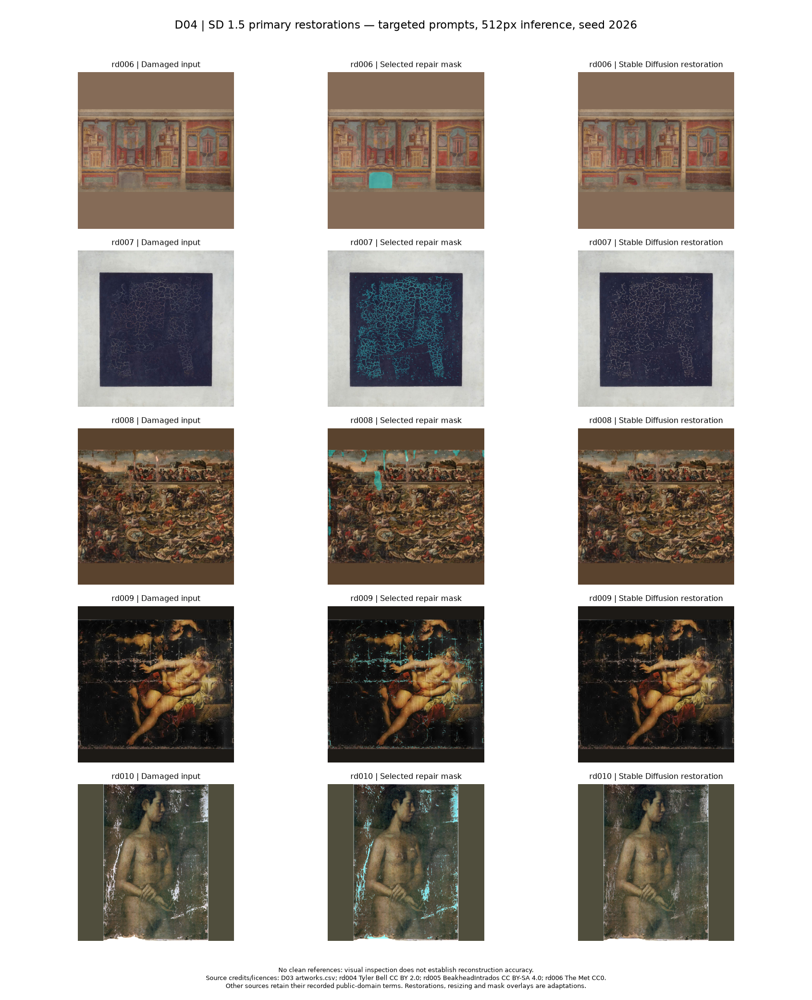

SD primary restorations completed: 10
Validation checks passed: 216
Candidate table: outputs\d04_real_damage_restoration_and_evaluation\data\candidates.csv


In [23]:
D04_SD_PREVIEW_PATHS = rds.render_previews(D04_SD)

for preview_path in D04_SD_PREVIEW_PATHS:
    display(NotebookImage(
        filename=str(preview_path),
        width=1150,
    ))

rds.release_pipeline(D04_SD)

D04_VALIDATION.raise_for_blocking()
D04_BATCH_6_READY = True

print(
    "SD primary restorations completed:",
    D04_SD["summary"]["completed_candidates"],
)
print(
    "Validation checks passed:",
    D04_VALIDATION.summary()["passed_count"],
)
print(
    "Candidate table:",
    D04_OUTPUTS["candidates"].relative_to(PROJECT_ROOT),
)

## Batch 7 — Fixed-prompt repeated-seed Stable Diffusion

This batch completes the four-seed Stable Diffusion groups for the ten
physical-damage paintings. The verified seed-2026 primary restorations
from Batch 6 are reused. Three additional candidates per painting use
seeds 2027, 2028 and 2029.

Within each group, the damaged input, reviewed mask, targeted prompt,
negative prompt, checkpoint and numerical generation settings remain
fixed. Only the random seed changes. The saved Batch 6 smoke checks
are revalidated without repeating smoke inference.

Each additional candidate is checkpointed separately. Verified outputs
can be resumed, and the forty existing primary candidates are preserved.
No candidate is selected or discarded based on its visual appearance.

The completed collection contains seventy candidates: forty primary
and thirty additional. The forty SD candidates form ten four-seed
groups, providing sixty unique unordered seed pairs.

This batch saves group membership, pair plans and visual comparisons.
Variability measurements are computed in Batch 8. Repeated candidates
describe stochastic variation; they do not provide clean references,
calibrated confidence or independent additional paintings.

In [24]:
import importlib
from pathlib import Path

import pandas as pd
from IPython.display import display, Image as NotebookImage
from restoration_eval import real_damage_sd_seeds

if not globals().get("D04_BATCH_6_READY", False):
    raise RuntimeError("D04 Batch 6 has not passed in this kernel.")

D04_BATCH_7_READY = False
rds7 = importlib.reload(real_damage_sd_seeds)

EXPECTED_SD_SEEDS_HELPER = (
    PROJECT_ROOT / "src/restoration_eval/real_damage_sd_seeds.py"
).resolve()

if Path(rds7.__file__).resolve() != EXPECTED_SD_SEEDS_HELPER:
    raise RuntimeError("SD seed adapter came from another checkout.")

if "D04_SD_SEEDS" in globals():
    rds7.release_pipeline(D04_SD_SEEDS)

D04_SD_SEEDS_CONFIG_PATH = (
    PROJECT_ROOT / "config/experiments/real_damage_sd_seeds.yaml"
)

D04_SD_SEEDS = rds7.prepare_seeds(
    PROJECT_ROOT,
    D04_SD_SEEDS_CONFIG_PATH,
)

display(pd.DataFrame([D04_SD_SEEDS["validation"].summary()]))

display(
    D04_SD_SEEDS["worklist"]
    .groupby(["painting_id", "prompt_id"])["seed"]
    .agg(list)
    .rename("additional_seeds")
    .reset_index()
    .assign(reused_primary_seed=2026)
)

print(
    "Inventory run:",
    D04_SD_SEEDS["inventory"]["inventory_run_id"],
)
print(
    "Additional SD candidates:",
    len(D04_SD_SEEDS["worklist"]),
)
print(
    "Verified primary SD candidates reused:",
    len(D04_SD_SEEDS["primary_records"]),
)

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,221,221,0,0,True,[]


,painting_id,prompt_id,additional_seeds,reused_primary_seed
0,rd001,d04_targeted_rd001_v1,"[2027, 2028, 2029]",2026
1,rd002,d04_targeted_rd002_v1,"[2027, 2028, 2029]",2026
2,rd003,d04_targeted_rd003_v1,"[2027, 2028, 2029]",2026
3,rd004,d04_targeted_rd004_v1,"[2027, 2028, 2029]",2026
4,rd005,d04_targeted_rd005_v1,"[2027, 2028, 2029]",2026
5,rd006,d04_targeted_rd006_v1,"[2027, 2028, 2029]",2026
6,rd007,d04_targeted_rd007_v1,"[2027, 2028, 2029]",2026
7,rd008,d04_targeted_rd008_v1,"[2027, 2028, 2029]",2026
8,rd009,d04_targeted_rd009_v1,"[2027, 2028, 2029]",2026
9,rd010,d04_targeted_rd010_v1,"[2027, 2028, 2029]",2026


Inventory run: inventory_20261115T141135Z_5306c64d
Additional SD candidates: 30
Verified primary SD candidates reused: 10


In [25]:
D04_SD_SEEDS = rds7.run_candidates(D04_SD_SEEDS)
D04_SD_SEEDS = rds7.validate_results(D04_SD_SEEDS)

D04_VALIDATION = D04_SD_SEEDS["validation"]

display(
    D04_SD_SEEDS["records"][[
        "painting_id",
        "seed",
        "status",
        "changed_inside_pixels",
        "changed_outside_pixels",
        "inside_change_fraction",
        "retry_count",
        "runtime_seconds",
    ]]
)

display(pd.DataFrame([{
    key: D04_SD_SEEDS["summary"][key]
    for key in (
        "completed_candidates",
        "failed_candidates",
        "reused_candidates",
        "reused_primary_candidates",
        "completed_seed_groups",
        "planned_unique_seed_pairs",
        "recorded_case_runtime_seconds",
        "runtime_scope",
    )
}]))

D04_CANDIDATES = pd.read_csv(
    D04_OUTPUTS["candidates"],
    keep_default_na=False,
    float_precision="round_trip",
)

display(
    D04_CANDIDATES.groupby(
        ["model_id", "candidate_role", "status"],
        dropna=False,
    ).size().rename("candidate_count").reset_index()
)

D04_SEED_GROUP_MEMBERS = D04_SD_SEEDS["group_members"]
D04_SEED_PAIR_PLAN = D04_SD_SEEDS["seed_pair_plan"]

display(
    D04_SEED_GROUP_MEMBERS.groupby("painting_id").agg(
        candidate_count=("candidate_id", "size"),
        seeds=("seed", list),
    ).reset_index()
)

display(pd.DataFrame([D04_VALIDATION.summary()]))

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]D:\Masters\FH\Thesis\painting-restoration-eval\.venv\Lib\site-packages\diffusers\models\modeling_utils.py:110: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub fo

SD additional 1/30 | rd001 | seed 2027 | completed | reused=False


100%|██████████| 30/30 [00:13<00:00,  2.27it/s]


SD additional 2/30 | rd001 | seed 2028 | completed | reused=False


100%|██████████| 30/30 [00:13<00:00,  2.30it/s]


SD additional 3/30 | rd001 | seed 2029 | completed | reused=False


... (55 outputs left out)

,completed_candidates,failed_candidates,reused_candidates,reused_primary_candidates,completed_seed_groups,planned_unique_seed_pairs,recorded_case_runtime_seconds,runtime_scope
0,30,0,0,10,10,60,412.702367,additional_seed_case_calls_only_excludes_model...


,model_id,candidate_role,status,candidate_count
0,hint_places2,primary,completed,10
1,lama,primary,completed,10
2,opencv_telea,primary,completed,10
3,stable_diffusion_inpainting,additional_seed,completed,30
4,stable_diffusion_inpainting,primary,completed,10


,painting_id,candidate_count,seeds
0,rd001,4,"[2026, 2027, 2028, 2029]"
1,rd002,4,"[2026, 2027, 2028, 2029]"
2,rd003,4,"[2026, 2027, 2028, 2029]"
3,rd004,4,"[2026, 2027, 2028, 2029]"
4,rd005,4,"[2026, 2027, 2028, 2029]"
5,rd006,4,"[2026, 2027, 2028, 2029]"
6,rd007,4,"[2026, 2027, 2028, 2029]"
7,rd008,4,"[2026, 2027, 2028, 2029]"
8,rd009,4,"[2026, 2027, 2028, 2029]"
9,rd010,4,"[2026, 2027, 2028, 2029]"


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,325,325,0,0,True,[]


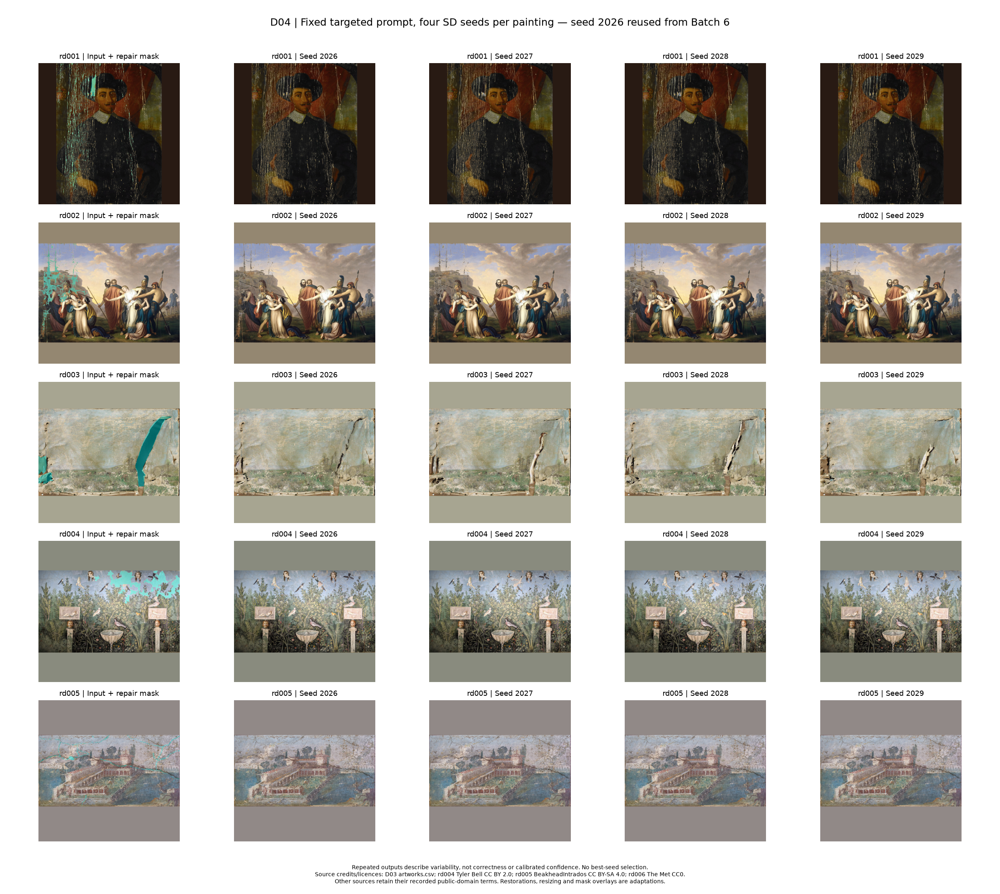

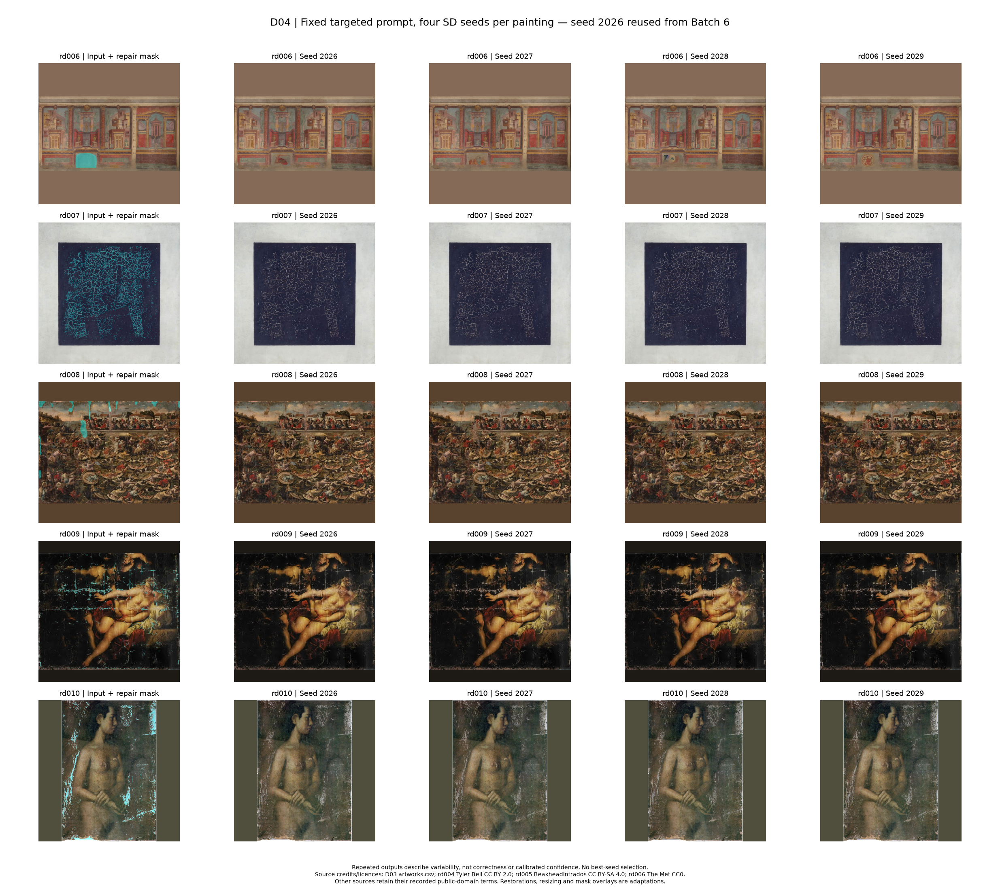

Additional SD restorations completed: 30
Complete four-seed groups: 10
Unique seed pairs: 60
Validation checks passed: 325


In [26]:
D04_SD_SEEDS_PREVIEW_PATHS = rds7.render_previews(D04_SD_SEEDS)

for preview_path in D04_SD_SEEDS_PREVIEW_PATHS:
    display(NotebookImage(
        filename=str(preview_path),
        width=1500,
    ))

rds7.release_pipeline(D04_SD_SEEDS)

D04_VALIDATION.raise_for_blocking()
D04_BATCH_7_READY = True

print(
    "Additional SD restorations completed:",
    D04_SD_SEEDS["summary"]["completed_candidates"],
)
print(
    "Complete four-seed groups:",
    D04_SD_SEEDS["summary"]["completed_seed_groups"],
)
print("Unique seed pairs:", len(D04_SEED_PAIR_PLAN))
print(
    "Validation checks passed:",
    D04_VALIDATION.summary()["passed_count"],
)

## Batch 8 — Reference-free diagnostics and seed variability

The physical-damage paintings have no clean reference. This batch therefore
separates technical preservation, edit and boundary descriptors, and
disagreement between repeated Stable Diffusion candidates.

All seventy candidates receive outside-mask preservation checks and
measurements of changes within the selected repair region. These changes
describe edit magnitude, not reconstruction error. The forty primary
restorations remain separate from the additional SD seeds.

Boundary descriptors compare mean colours in the canonical three-pixel
inner and outer boundary bands. Absolute L* differences and CIEDE2000
describe raw contrast. Natural object edges can also produce large
contrasts, so lower values do not establish a better restoration.

The forty SD candidates form ten four-seed groups. Their targeted prompts,
inputs, masks and generation settings remain fixed. Existing N18/N19
helpers compute pairwise RGB differences and spatial standard deviation.
LPIPS compares generated candidates with one another using the existing
N14 configuration; it does not compare them against an assumed original.

Pixel measurements cover content, repaired pixels, the mask bounding-box
crop, the boundary ring and outside-mask content. LPIPS uses contiguous
content and mask-bounding-box crops. Canvas padding is excluded.

The sixty unique pairs produce 720 measurement rows across metrics and
regions, together with 220 group-summary rows and ten raw variability maps.
These rows are not independent additional paintings.

Map previews share one colour scale, capped at the pooled masked
99th percentile for display. Numerical arrays remain unclipped.
Repeated-seed agreement is not correctness or calibrated confidence.
The masks identify selected repair targets rather than exhaustive
condition maps of every damaged area.

In [27]:
import importlib
from pathlib import Path

import pandas as pd
from IPython.display import display, Image as NotebookImage
from restoration_eval import real_damage_diagnostics

if not globals().get("D04_BATCH_7_READY", False):
    raise RuntimeError("D04 Batch 7 has not passed in this kernel.")

D04_BATCH_8_READY = False
rdd8 = importlib.reload(real_damage_diagnostics)

EXPECTED_DIAGNOSTICS_HELPER = (
    PROJECT_ROOT / "src/restoration_eval/real_damage_diagnostics.py"
).resolve()

if Path(rdd8.__file__).resolve() != EXPECTED_DIAGNOSTICS_HELPER:
    raise RuntimeError("Diagnostics helper came from another checkout.")

D04_DIAGNOSTICS_CONFIG_PATH = (
    PROJECT_ROOT / "config/evaluation/real_damage_diagnostics.yaml"
)

D04_DIAGNOSTICS = rdd8.prepare_diagnostics(
    PROJECT_ROOT,
    D04_DIAGNOSTICS_CONFIG_PATH,
)

display(pd.DataFrame([D04_DIAGNOSTICS["validation"].summary()]))

display(
    D04_DIAGNOSTICS["candidates"]
    .groupby(["model_id", "candidate_role"])
    .size()
    .rename("candidate_count")
    .reset_index()
)

print(
    "Inventory run:",
    D04_DIAGNOSTICS["inventory"]["inventory_run_id"],
)
print("Verified candidates:", len(D04_DIAGNOSTICS["candidates"]))
print("Region records:", len(D04_DIAGNOSTICS["region_manifest"]))

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,331,331,0,0,True,[]


,model_id,candidate_role,candidate_count
0,hint_places2,primary,10
1,lama,primary,10
2,opencv_telea,primary,10
3,stable_diffusion_inpainting,additional_seed,30
4,stable_diffusion_inpainting,primary,10


Inventory run: inventory_20261115T205730Z_c71d7d13
Verified candidates: 70
Region records: 70


In [28]:
D04_DIAGNOSTICS = rdd8.run_diagnostics(D04_DIAGNOSTICS)

D04_TECHNICAL_CHECKS = D04_DIAGNOSTICS["technical"]
D04_REFERENCE_FREE_DIAGNOSTICS = D04_DIAGNOSTICS["diagnostics"]

display(
    D04_TECHNICAL_CHECKS.groupby(
        ["model_id", "candidate_role"]
    ).agg(
        candidates=("candidate_id", "size"),
        maximum_changed_outside_pixels=("changed_outside_pixels", "max"),
        maximum_changed_padding_pixels=("changed_padding_pixels", "max"),
    ).reset_index()
)

display(
    D04_REFERENCE_FREE_DIAGNOSTICS.loc[
        D04_REFERENCE_FREE_DIAGNOSTICS["candidate_role"].eq("primary"),
        [
            "painting_id",
            "model_id",
            "masked_edit_rgb_mean",
            "masked_edit_rgb_p95",
            "inside_change_fraction",
        ],
    ]
    .sort_values(["painting_id", "model_id"])
    .reset_index(drop=True)
    .round(6)
)

print("Technical records:", len(D04_TECHNICAL_CHECKS))
print("Reference-free diagnostic records:", len(D04_REFERENCE_FREE_DIAGNOSTICS))

Reference-free candidate diagnostics: 10/70
Reference-free candidate diagnostics: 20/70
Reference-free candidate diagnostics: 30/70
Reference-free candidate diagnostics: 40/70
Reference-free candidate diagnostics: 50/70
Reference-free candidate diagnostics: 60/70
Reference-free candidate diagnostics: 70/70


,model_id,candidate_role,candidates,maximum_changed_outside_pixels,maximum_changed_padding_pixels
0,hint_places2,primary,10,0,0
1,lama,primary,10,0,0
2,opencv_telea,primary,10,0,0
3,stable_diffusion_inpainting,additional_seed,30,0,0
4,stable_diffusion_inpainting,primary,10,0,0


,painting_id,model_id,masked_edit_rgb_mean,masked_edit_rgb_p95,inside_change_fraction
0,rd001,hint_places2,0.171383,0.367320,1.000000
1,rd001,lama,0.211816,0.394771,1.000000
2,rd001,opencv_telea,0.312135,0.478431,0.999918
3,rd001,stable_diffusion_inpainting,0.249242,0.486275,1.000000
4,rd002,hint_places2,0.074209,0.185621,0.999655
5,rd002,lama,0.074486,0.183007,1.000000
6,rd002,opencv_telea,0.093500,0.215686,0.999862
7,rd002,stable_diffusion_inpainting,0.090372,0.214379,1.000000
8,rd003,hint_places2,0.274577,0.552941,1.000000
9,rd003,lama,0.233940,0.504575,0.999962


Technical records: 70
Reference-free diagnostic records: 70


In [29]:
D04_DIAGNOSTICS = rdd8.run_uncertainty(D04_DIAGNOSTICS)

D04_SEED_PAIRWISE = D04_DIAGNOSTICS["seed_pairwise"]
D04_UNCERTAINTY_SUMMARY = D04_DIAGNOSTICS["uncertainty_summary"]

D04_MASKED_VARIABILITY = D04_UNCERTAINTY_SUMMARY.loc[
    D04_UNCERTAINTY_SUMMARY["region_id"].eq("masked_region")
    & D04_UNCERTAINTY_SUMMARY["metric_name"].isin([
        "pixel_rgb_std_mean",
        "pixel_rgb_std_p95",
        "pairwise_rgb_mae",
        "pairwise_rgb_rmse",
    ])
]

display(
    D04_MASKED_VARIABILITY.pivot(
        index="painting_id",
        columns="metric_name",
        values="value",
    ).round(6)
)

display(
    D04_UNCERTAINTY_SUMMARY.loc[
        D04_UNCERTAINTY_SUMMARY["metric_name"].eq(
            "pairwise_lpips_distance"
        )
    ].pivot(
        index="painting_id",
        columns="region_id",
        values="value",
    ).round(6)
)

print("Unique seed pairs:", len(
    D04_SEED_PAIRWISE[
        ["uncertainty_group_id", "candidate_id_a", "candidate_id_b"]
    ].drop_duplicates()
))
print("Pairwise measurement rows:", len(D04_SEED_PAIRWISE))
print("Group-summary rows:", len(D04_UNCERTAINTY_SUMMARY))
print("Raw variability maps:", len(D04_DIAGNOSTICS["maps"]))

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: D:\Masters\FH\Thesis\painting-restoration-eval\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


D:\Masters\FH\Thesis\painting-restoration-eval\.venv\Lib\site-packages\lpips\lpips.py:107: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(mode

SD seed variability: 1/10 groups | rd010
SD seed variability: 2/10 groups | rd008
SD seed variability: 3/10 groups | rd007
SD seed variability: 4/10 groups | rd009
SD seed variability: 5/10 groups | rd005
SD seed variability: 6/10 groups | rd001
SD seed variability: 7/10 groups | rd006
SD seed variability: 8/10 groups | rd002
SD seed variability: 9/10 groups | rd004
SD seed variability: 10/10 groups | rd003


metric_name,pairwise_rgb_mae,pairwise_rgb_rmse,pixel_rgb_std_mean,pixel_rgb_std_p95
painting_id,,,,
rd001,0.095477,0.135375,0.068108,0.164521
rd002,0.076727,0.108225,0.054502,0.129089
rd003,0.154733,0.214857,0.110768,0.245653
rd004,0.085199,0.128260,0.061589,0.156293
rd005,0.066386,0.096490,0.047088,0.120008
rd006,0.056252,0.078483,0.040249,0.084480
rd007,0.114819,0.161960,0.082239,0.186434
rd008,0.065354,0.087560,0.046463,0.095452
rd009,0.092232,0.134191,0.065684,0.166355


region_id,content_region,mask_bbox_crop
painting_id,,
rd001,0.008657,0.011482
rd002,0.008664,0.039136
rd003,0.077079,0.085802
rd004,0.022745,0.130143
rd005,0.005409,0.005409
rd006,0.009896,0.360472
rd007,0.025499,0.082936
rd008,0.005546,0.006704
rd009,0.007490,0.007490


Unique seed pairs: 60
Pairwise measurement rows: 720
Group-summary rows: 220
Raw variability maps: 10


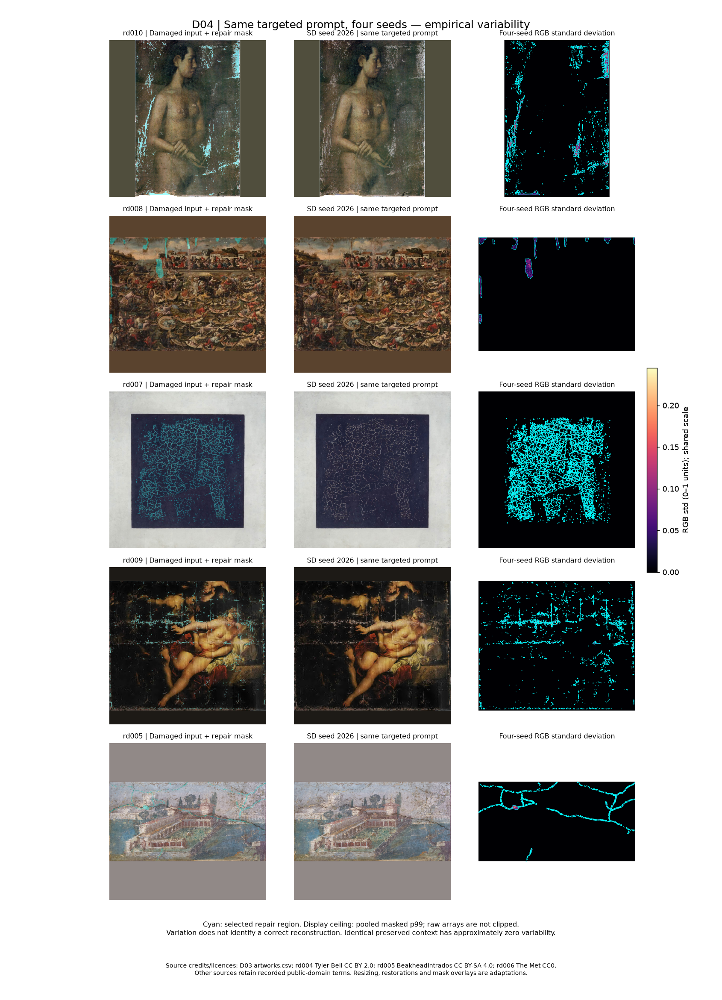

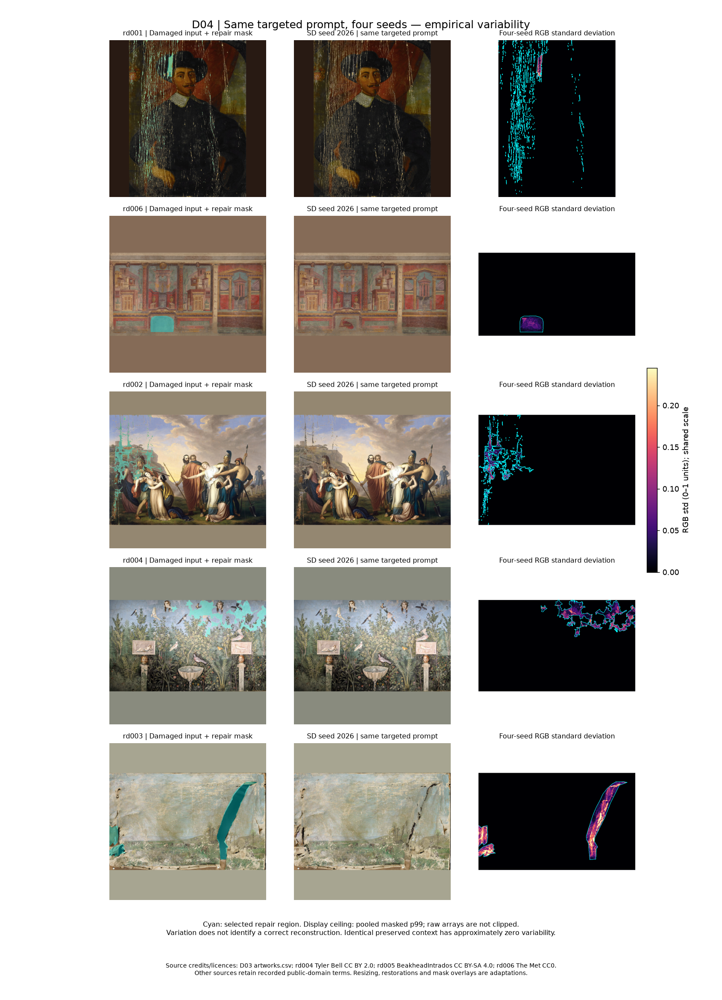

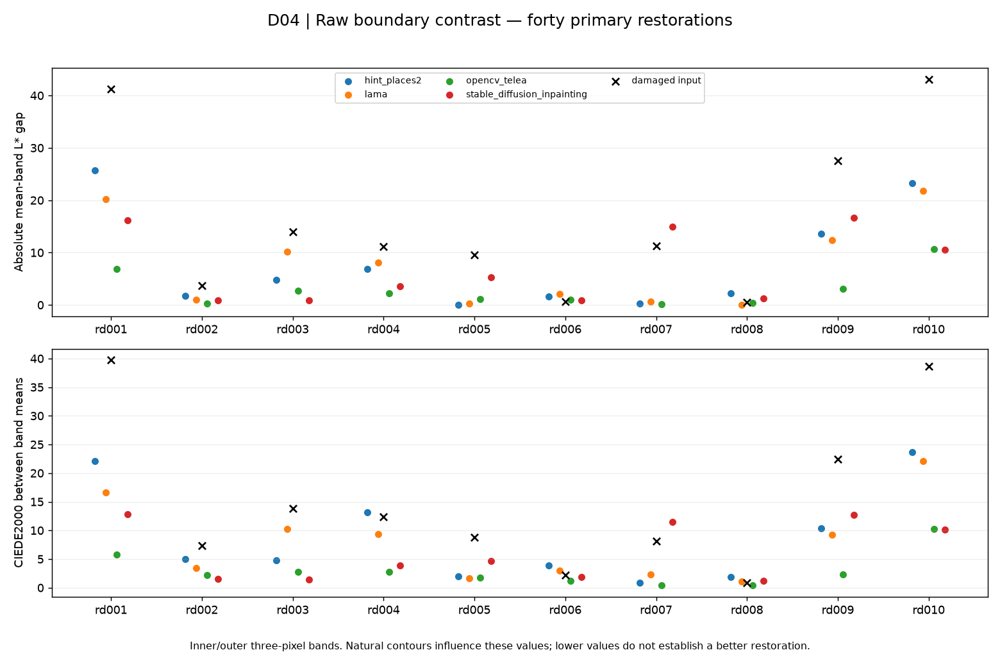

,completed_candidates,primary_candidates,sd_candidates,completed_seed_groups,unique_seed_pairs,pairwise_rows,group_summary_rows,map_count,reused_candidate_diagnostics,reused_uncertainty_groups
0,70,40,40,10,60,720,220,10,0,0


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,371,371,0,0,True,[]


Batch 8 validation passed: True
Diagnostic output directory: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d04_real_damage_restoration_and_evaluation\work\diagnostics


In [30]:
D04_DIAGNOSTIC_PREVIEW_PATHS = rdd8.render_outputs(
    D04_DIAGNOSTICS
)

D04_DIAGNOSTICS_SUMMARY = rdd8.validate_results(
    D04_DIAGNOSTICS
)

D04_VALIDATION = D04_DIAGNOSTICS["validation"]

for preview_path in D04_DIAGNOSTIC_PREVIEW_PATHS:
    display(NotebookImage(
        filename=str(preview_path),
        width=1300,
    ))

display(pd.DataFrame([{
    key: D04_DIAGNOSTICS_SUMMARY[key]
    for key in (
        "completed_candidates",
        "primary_candidates",
        "sd_candidates",
        "completed_seed_groups",
        "unique_seed_pairs",
        "pairwise_rows",
        "group_summary_rows",
        "map_count",
        "reused_candidate_diagnostics",
        "reused_uncertainty_groups",
    )
}]))

display(pd.DataFrame([D04_VALIDATION.summary()]))

D04_VALIDATION.raise_for_blocking()
D04_BATCH_8_READY = True

print("Batch 8 validation passed:", D04_BATCH_8_READY)
print(
    "Diagnostic output directory:",
    D04_DIAGNOSTICS["output_root"] / "work/diagnostics",
)

## Batch 9 — Descriptive physical and synthetic comparison

This batch compares the ten physical-damage cases with the ten synthetic
cases selected from input geometry in Batch 2, before the physical
restorations were generated. The selections and existing restorations
remain unchanged.

Each pair contains four primary physical restorations and four existing
synthetic restorations: Telea, LaMa, HINT and Stable Diffusion. Additional
SD seeds remain part of the separate variability analysis.

The comparison retains differences in artwork, damage origin, mask
coverage and fragmentation. Similar coverage does not make two damage
patterns equivalent. Physical SD candidates use the approved targeted
prompts; synthetic SD candidates retain their original generic prompts.
These differences prevent a causal claim about physical versus
synthetic restoration performance.

Batch 8's edit-magnitude and raw boundary-contrast definitions are also
applied to the synthetic candidates. They describe changes and transitions,
not reconstruction accuracy. Edit magnitudes use normalized RGB values
between zero and one.

Reference-based evidence is available only for the synthetic cases.
Saved masked MAE, crop SSIM and crop LPIPS are copied from N13/N14 using
exact candidate, case and model identifiers. These metrics are not
recomputed. Saved synthetic MAE uses RGB values on the zero-to-255 scale.
Physical reference scores remain explicitly unavailable.

Full-context panels show the damaged inputs, four restorations and the
synthetic clean reference. Detail panels use the largest connected
input-mask component with a 32-pixel margin, clipped to image content.
These independent display crops are not corresponding subjects or new
evaluation regions. Displayed scores always retain their original regions.

The outputs support case-level inspection without pooling the populations,
creating a combined quality score or treating physical plausibility as
verified historical correctness.

In [31]:
import importlib
from pathlib import Path

import pandas as pd
from IPython.display import display, Image as NotebookImage
from restoration_eval import real_damage_comparison

if not globals().get("D04_BATCH_8_READY", False):
    raise RuntimeError("D04 Batch 8 has not passed in this kernel.")

D04_BATCH_9_READY = False
rdc9 = importlib.reload(real_damage_comparison)

EXPECTED_COMPARISON_HELPER = (
    PROJECT_ROOT / "src/restoration_eval/real_damage_comparison.py"
).resolve()

if Path(rdc9.__file__).resolve() != EXPECTED_COMPARISON_HELPER:
    raise RuntimeError("Comparison helper came from another checkout.")

D04_COMPARISON_CONFIG_PATH = (
    PROJECT_ROOT / "config/evaluation/real_damage_comparison.yaml"
)

D04_COMPARISON = rdc9.prepare_comparison(
    PROJECT_ROOT,
    D04_COMPARISON_CONFIG_PATH,
    diagnostics_context=D04_DIAGNOSTICS,
)

display(pd.DataFrame([D04_COMPARISON["validation"].summary()]))

D04_MATCHES = D04_COMPARISON["selection"]

display(
    D04_MATCHES.assign(
        physical_mask_pct=100 * D04_MATCHES["real_damage_fraction"],
        synthetic_mask_pct=100 * D04_MATCHES["synthetic_damage_fraction"],
    )[[
        "painting_id",
        "synthetic_painting_id",
        "category",
        "synthetic_mask_type",
        "physical_mask_pct",
        "synthetic_mask_pct",
        "real_component_count",
        "synthetic_component_count",
    ]].round(3)
)

print("Inventory run:", D04_COMPARISON["inventory"]["inventory_run_id"])
print("Frozen comparison pairs:", len(D04_MATCHES))
print("Existing synthetic candidates:", len(D04_COMPARISON["synthetic_plan"]))
print("Saved reference measurements:", len(D04_COMPARISON["reference_metrics"]))

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,375,375,0,0,True,[]


,painting_id,synthetic_painting_id,category,synthetic_mask_type,physical_mask_pct,synthetic_mask_pct,real_component_count,synthetic_component_count
0,rd001,p282,portrait_figure,scratch_thin,2.755,2.885,669,9
1,rd002,p001,portrait_figure,loss_small,3.499,3.415,151,6
2,rd003,p195,landscape_natural,mixed_damage,7.209,8.062,3,7
3,rd004,p014,landscape_natural,loss_small,6.371,5.827,6,5
4,rd005,p119,architecture_structured,scratch_thin,2.159,2.333,370,9
5,rd006,p130,architecture_structured,loss_small,2.736,3.066,1,4
6,rd007,p054,abstraction_surrealism,mixed_damage,7.827,8.211,1006,10
7,rd008,p082,abstraction_surrealism,scratch_thin,2.025,2.133,12,9
8,rd009,p243,high_texture_brushwork,scratch_thin,2.571,2.700,1394,11
9,rd010,p210,high_texture_brushwork,loss_small,3.674,3.676,1002,7


Inventory run: inventory_20261115T213336Z_352efafa
Frozen comparison pairs: 10
Existing synthetic candidates: 40
Saved reference measurements: 120


In [32]:
D04_COMPARISON = rdc9.run_comparison(D04_COMPARISON)

D04_COMPARISON_TABLE = D04_COMPARISON["comparison"]

display(
    D04_COMPARISON_TABLE[[
        "pair_id",
        "model_id",
        "physical_masked_edit_rgb_mean",
        "synthetic_masked_edit_rgb_mean",
        "physical_restored_boundary_Lstar_gap",
        "synthetic_restored_boundary_Lstar_gap",
    ]]
    .sort_values(["pair_id", "model_id"])
    .reset_index(drop=True)
    .round(6)
)

display(
    D04_COMPARISON_TABLE[[
        "pair_id",
        "synthetic_painting_id",
        "model_id",
        "synthetic_masked_mae",
        "synthetic_crop_ssim",
        "synthetic_crop_lpips",
    ]]
    .sort_values(["pair_id", "model_id"])
    .reset_index(drop=True)
    .round(6)
)

display(
    D04_COMPARISON["synthetic_technical"]
    .groupby("model_id")
    .agg(
        candidates=("candidate_id", "size"),
        maximum_changed_outside_pixels=("changed_outside_pixels", "max"),
        maximum_changed_padding_pixels=("changed_padding_pixels", "max"),
    )
    .reset_index()
)

print("Comparison rows:", len(D04_COMPARISON_TABLE))
print(
    "Physical reference-metric status:",
    D04_COMPARISON_TABLE["physical_reference_metric_status"].unique().tolist(),
)

Physical/synthetic comparison: 1/10 pairs | rd001
Physical/synthetic comparison: 2/10 pairs | rd002
Physical/synthetic comparison: 3/10 pairs | rd003
Physical/synthetic comparison: 4/10 pairs | rd004
Physical/synthetic comparison: 5/10 pairs | rd005
Physical/synthetic comparison: 6/10 pairs | rd006
Physical/synthetic comparison: 7/10 pairs | rd007
Physical/synthetic comparison: 8/10 pairs | rd008
Physical/synthetic comparison: 9/10 pairs | rd009
Physical/synthetic comparison: 10/10 pairs | rd010


,pair_id,model_id,physical_masked_edit_rgb_mean,synthetic_masked_edit_rgb_mean,physical_restored_boundary_Lstar_gap,synthetic_restored_boundary_Lstar_gap
0,rd001,hint_places2,0.171383,0.496807,25.668909,0.702636
1,rd001,lama,0.211816,0.501891,20.249756,0.137692
2,rd001,opencv_telea,0.312135,0.495521,6.866503,0.764692
3,rd001,stable_diffusion_inpainting,0.249242,0.512486,16.114477,1.693023
4,rd002,hint_places2,0.074209,0.883574,1.762294,0.366150
5,rd002,lama,0.074486,0.889534,0.973912,0.217303
6,rd002,opencv_telea,0.093500,0.883009,0.318198,0.091175
7,rd002,stable_diffusion_inpainting,0.090372,0.869606,0.820212,1.218864
8,rd003,hint_places2,0.274577,0.419452,4.738601,0.084859
9,rd003,lama,0.233940,0.404168,10.178128,0.229678


,pair_id,synthetic_painting_id,model_id,synthetic_masked_mae,synthetic_crop_ssim,synthetic_crop_lpips
0,rd001,p282,hint_places2,10.435871,0.987434,0.000850
1,rd001,p282,lama,11.134095,0.987544,0.000652
2,rd001,p282,opencv_telea,9.626804,0.990898,0.001043
3,rd001,p282,stable_diffusion_inpainting,31.308957,0.960707,0.030381
4,rd002,p001,hint_places2,5.593129,0.979721,0.009336
5,rd002,p001,lama,4.056897,0.985763,0.004462
6,rd002,p001,opencv_telea,4.744651,0.986460,0.011466
7,rd002,p001,stable_diffusion_inpainting,7.907618,0.977560,0.022704
8,rd003,p195,hint_places2,14.951327,0.948187,0.021933
9,rd003,p195,lama,13.812971,0.949879,0.025231


,model_id,candidates,maximum_changed_outside_pixels,maximum_changed_padding_pixels
0,hint_places2,10,0,0
1,lama,10,0,0
2,opencv_telea,10,0,0
3,stable_diffusion_inpainting,10,0,0


Comparison rows: 40
Physical reference-metric status: ['not_applicable_no_clean_reference']


Comparison panels: 1/10 | rd001
Comparison panels: 2/10 | rd002
Comparison panels: 3/10 | rd003
Comparison panels: 4/10 | rd004
Comparison panels: 5/10 | rd005
Comparison panels: 6/10 | rd006
Comparison panels: 7/10 | rd007
Comparison panels: 8/10 | rd008
Comparison panels: 9/10 | rd009
Comparison panels: 10/10 | rd010


,comparison_pairs,comparison_rows,physical_primary_candidates,synthetic_primary_candidates,saved_reference_metric_rows,full_panels,detail_panels,reused_metric_pairs,reused_panel_pairs
0,10,40,40,40,120,10,10,0,0


,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,393,393,0,0,True,[]


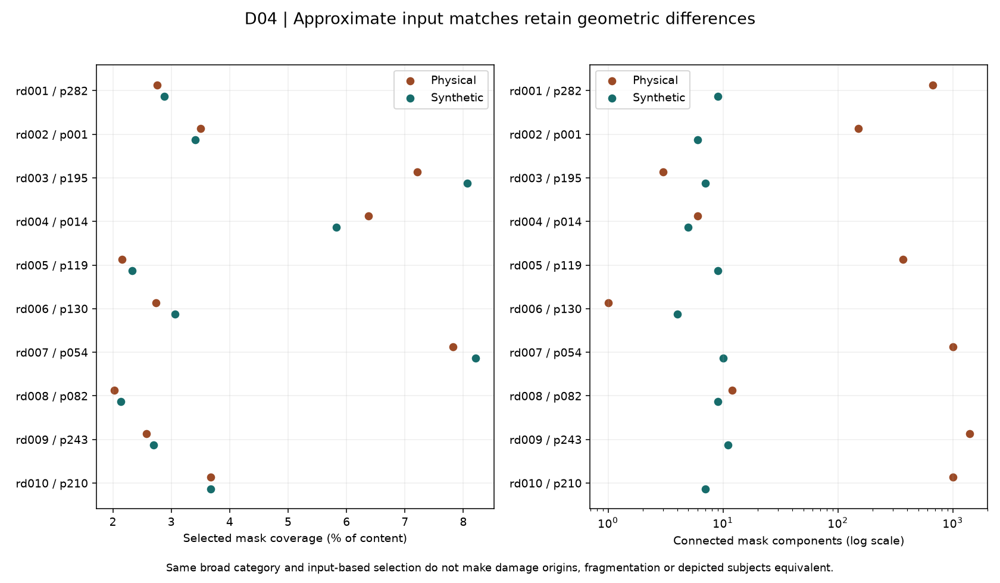

In [33]:
D04_COMPARISON_PANELS = rdc9.render_outputs(D04_COMPARISON)

D04_COMPARISON_SUMMARY = rdc9.validate_results(D04_COMPARISON)
D04_VALIDATION = D04_COMPARISON["validation"]

display(pd.DataFrame([{
    key: D04_COMPARISON_SUMMARY[key]
    for key in (
        "comparison_pairs",
        "comparison_rows",
        "physical_primary_candidates",
        "synthetic_primary_candidates",
        "saved_reference_metric_rows",
        "full_panels",
        "detail_panels",
        "reused_metric_pairs",
        "reused_panel_pairs",
    )
}]))

display(pd.DataFrame([D04_VALIDATION.summary()]))

display(NotebookImage(
    filename=str(D04_COMPARISON["matching_figure"]),
    width=1200,
))

D04_VALIDATION.raise_for_blocking()

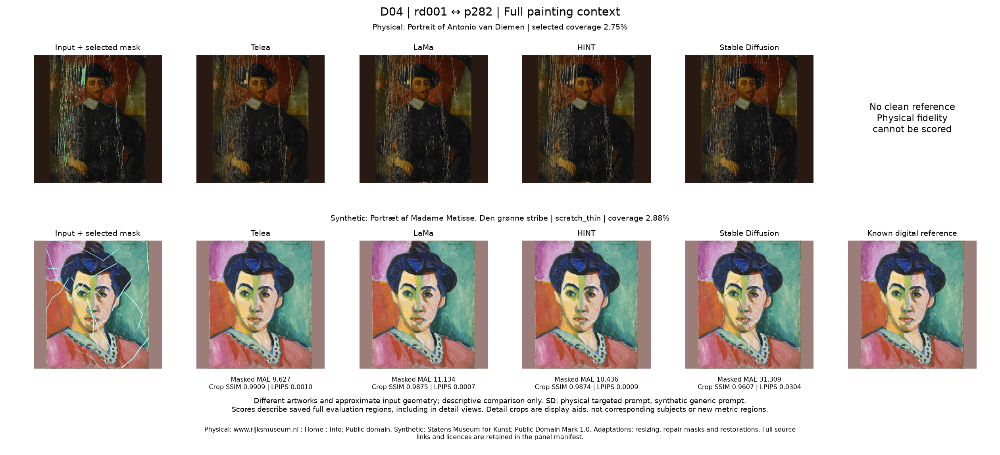

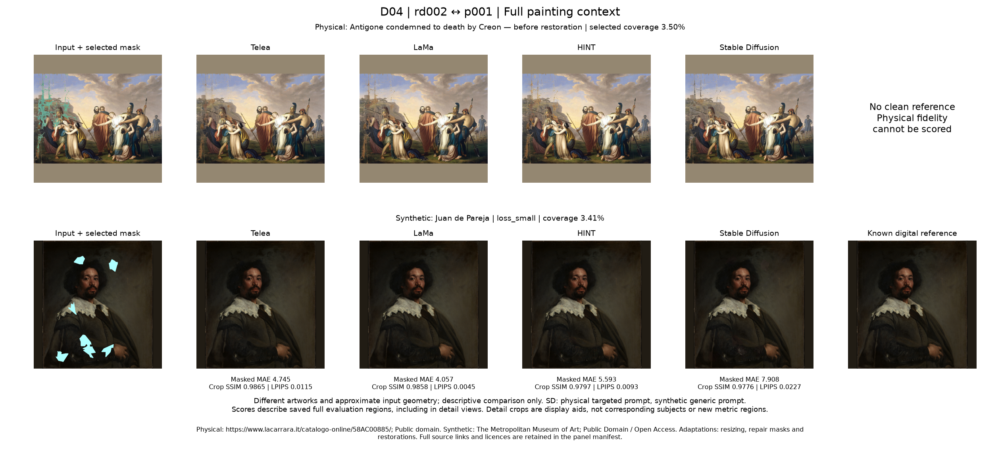

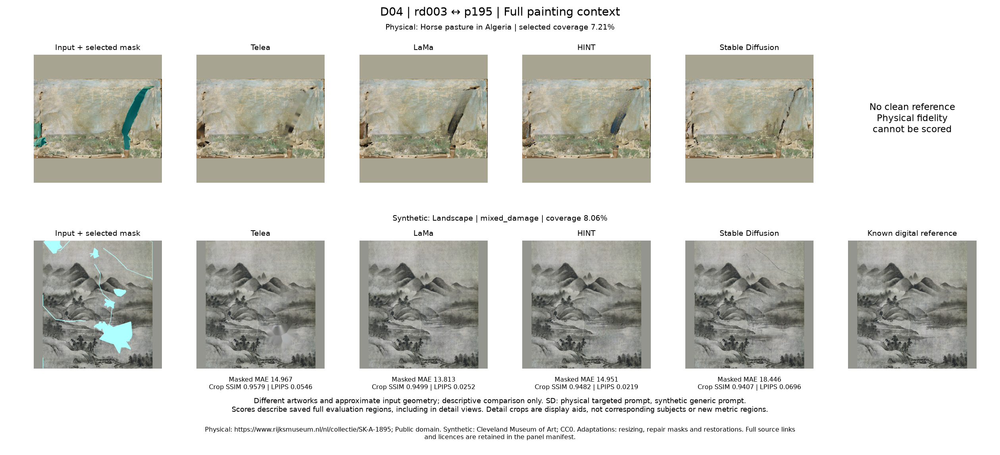

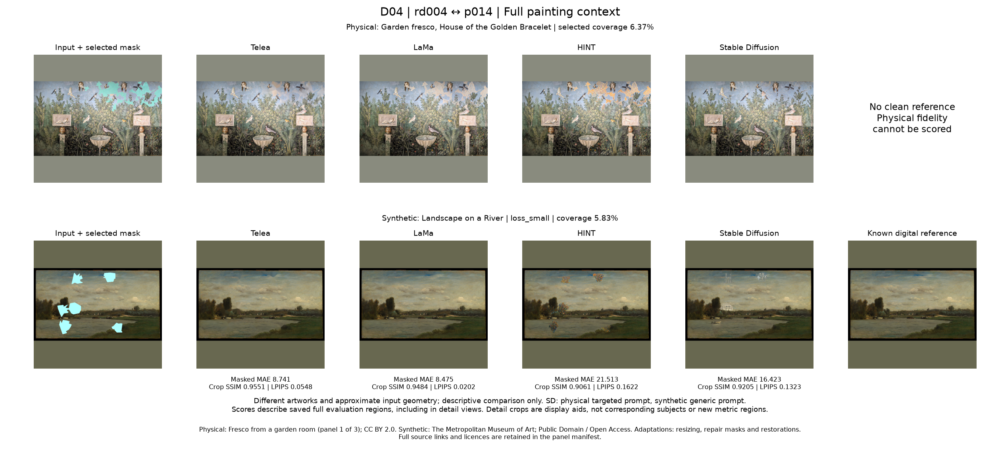

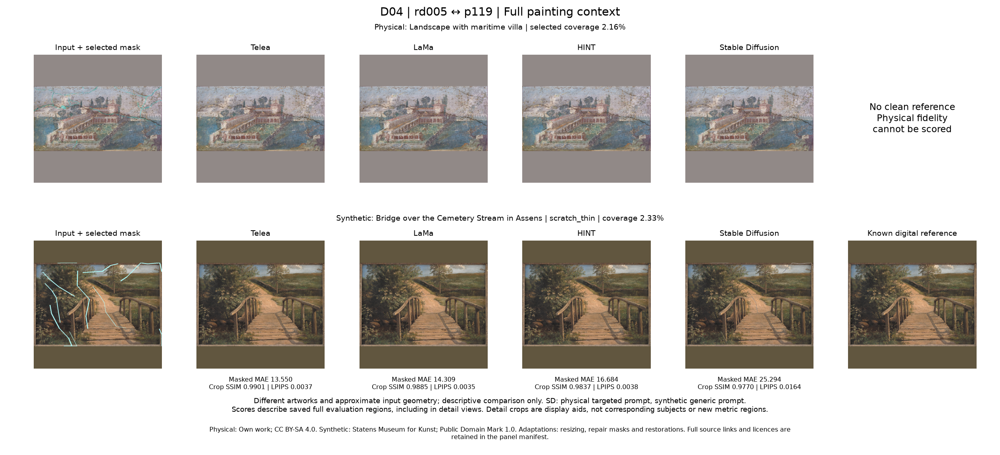

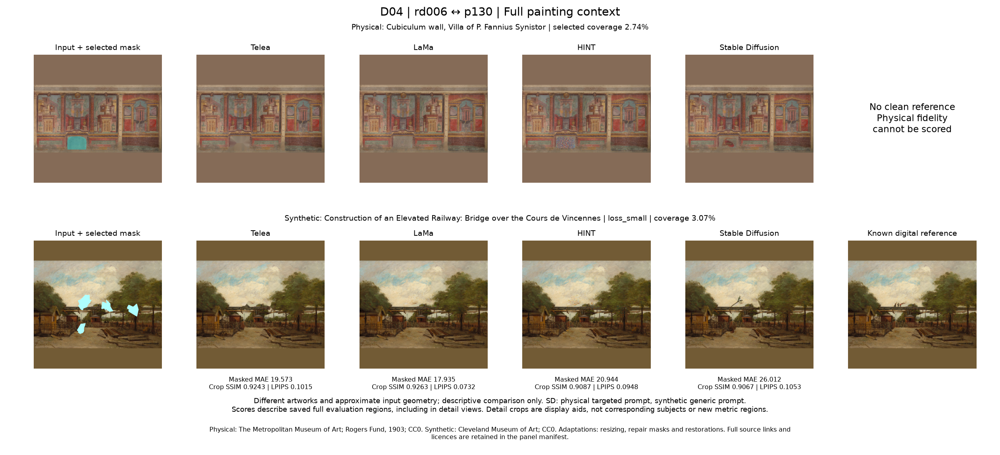

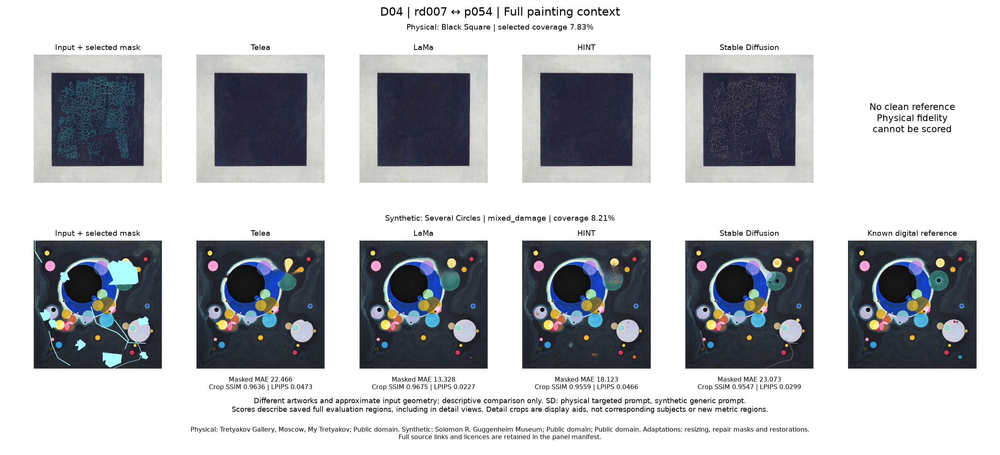

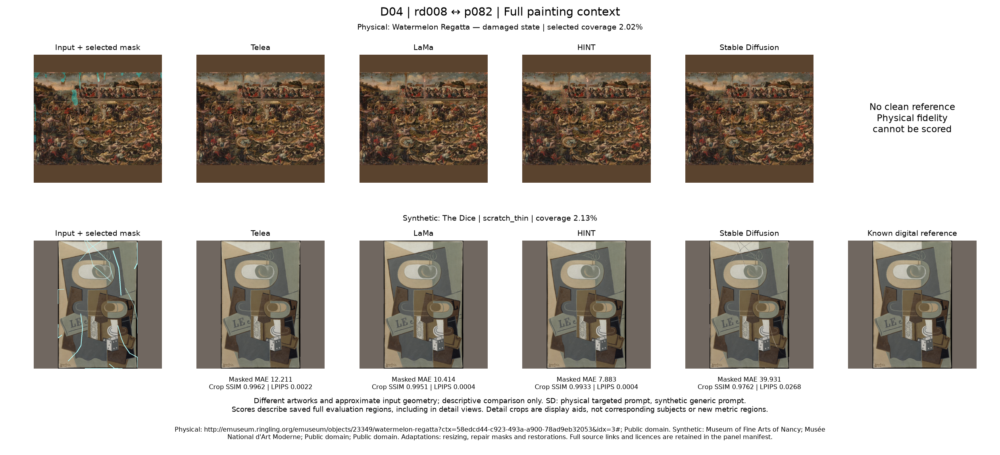

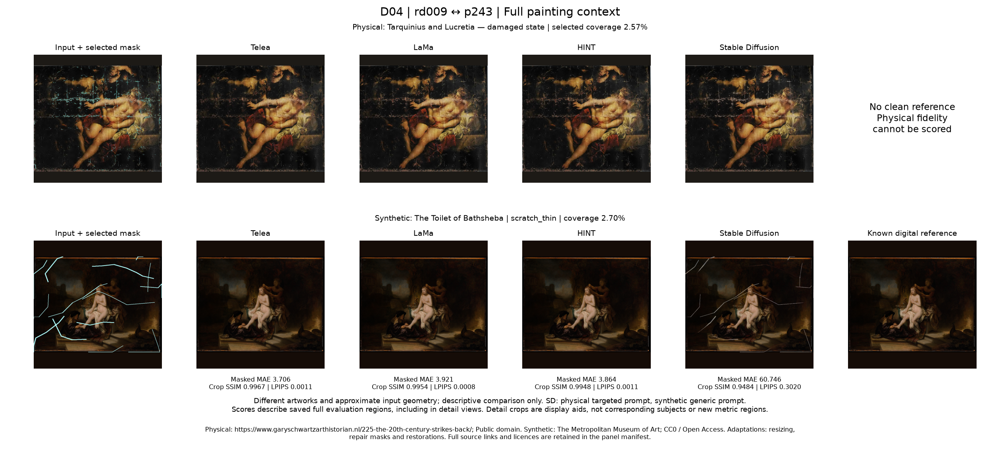

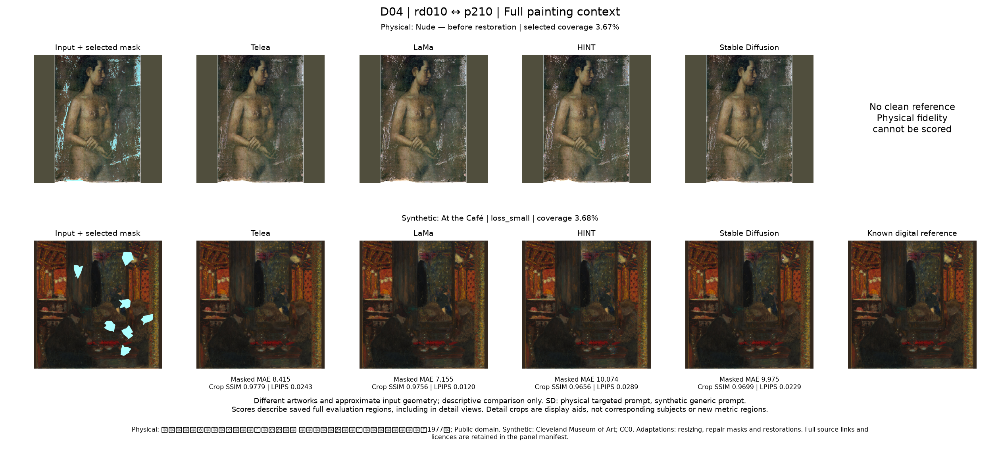

Batch 9 validation passed: True
Saved full-context panels: 10
Saved detail panels: 10


In [34]:
for panel in D04_COMPARISON_PANELS.sort_values("pair_id").itertuples():
    display(NotebookImage(
        filename=str(PROJECT_ROOT / panel.full_panel_path),
        width=1600,
    ))

D04_VALIDATION.raise_for_blocking()
D04_BATCH_9_READY = True

print("Batch 9 validation passed:", D04_BATCH_9_READY)
print("Saved full-context panels:", len(D04_COMPARISON_PANELS))
print("Saved detail panels:", len(D04_COMPARISON_PANELS))

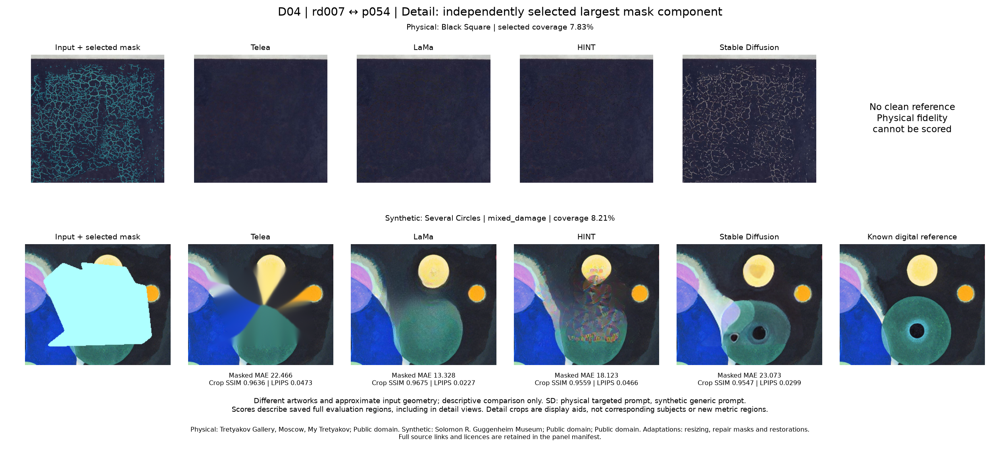

In [35]:
D04_DETAIL_PAINTING = "rd007"

D04_DETAIL_PANEL = D04_COMPARISON_PANELS.set_index("pair_id").loc[
    D04_DETAIL_PAINTING
]

display(NotebookImage(
    filename=str(PROJECT_ROOT / D04_DETAIL_PANEL["detail_panel_path"]),
    width=1600,
))

## Batch 10 — Final report and completion gate

This batch assembles the final report from the saved restoration,
diagnostic, variability and comparison evidence. It performs no new
inference or scientific metric calculation.

The report retains all ten physical paintings, four primary methods,
ten four-seed Stable Diffusion groups and ten frozen synthetic comparisons.
Full images, repair details, measurements and case-level interpretations
remain connected to their sources.

Qualitative observations represent researcher-approved assistant visual
inspection with model identities visible, not blinded expert ratings.
Physical fidelity remains unverifiable without clean references.
Differences between targeted physical and generic synthetic SD prompts
remain explicit.

The completion gate verifies source hashes, observations, numerical
claims, embedded images and approved report elements before writing the
final artifact manifest and completed run manifest.

In [36]:
import importlib
from pathlib import Path

import pandas as pd
from IPython.display import display
from restoration_eval import (
    real_damage_report,
    real_damage_report_content,
)

if not globals().get("D04_BATCH_9_READY", False):
    raise RuntimeError("D04 Batch 9 has not passed in this kernel.")

D04_BATCH_10_READY = False

rd_report_content = importlib.reload(real_damage_report_content)
rdr10 = importlib.reload(real_damage_report)

for module in (rd_report_content, rdr10):
    expected = (
        PROJECT_ROOT
        / "src/restoration_eval"
        / (module.__name__.rsplit(".", 1)[-1] + ".py")
    ).resolve()
    if Path(module.__file__).resolve() != expected:
        raise RuntimeError("Report helper came from another checkout.")

D04_REPORT = rdr10.prepare_report(
    PROJECT_ROOT,
    PROJECT_ROOT / "config/evaluation/real_damage_report.yaml",
    comparison_context=D04_COMPARISON,
)

display(pd.DataFrame([D04_REPORT["validation"].summary()]))

print("Inventory run:", D04_REPORT["inventory"]["inventory_run_id"])
print("Approved visual observations:", len(D04_REPORT["observations"]))
print("Report sections:", len(D04_REPORT["policy"]["sections"]))

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,396,396,0,0,True,[]


Inventory run: inventory_20261115T223320Z_d5bda8c0
Approved visual observations: 40
Report sections: 6


In [37]:
D04_REPORT_METADATA = rdr10.build_report(D04_REPORT)

display(pd.DataFrame([{
    key: D04_REPORT_METADATA[key]
    for key in (
        "embedded_images",
        "embedded_tiles",
        "numerical_claims",
        "approved_mock_elements",
        "report_size_bytes",
        "build_seconds",
    )
}]))

D04_REPORT_FILE = (
    D04_REPORT["output_root"]
    / D04_REPORT["config"]["outputs"]["report"]
)

print("Report:", D04_REPORT_FILE)

Report presentation panels: 1/10 paintings | rd001
Report presentation panels: 2/10 paintings | rd002
Report presentation panels: 3/10 paintings | rd003
Report presentation panels: 4/10 paintings | rd004
Report presentation panels: 5/10 paintings | rd005
Report presentation panels: 6/10 paintings | rd006
Report presentation panels: 7/10 paintings | rd007
Report presentation panels: 8/10 paintings | rd008
Report presentation panels: 9/10 paintings | rd009
Report presentation panels: 10/10 paintings | rd010


,embedded_images,embedded_tiles,numerical_claims,approved_mock_elements,report_size_bytes,build_seconds
0,46,481,161,83,29874479,44.258993


Report: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d04_real_damage_restoration_and_evaluation\reports\real_damage_evaluation.html


In [38]:
import webbrowser

D04_REPORT_CHECK = rdr10.validate_report(D04_REPORT)
D04_VALIDATION = D04_REPORT["validation"]

display(pd.DataFrame([D04_VALIDATION.summary()]))

D04_REPORT_TRACEABILITY = pd.read_csv(
    D04_REPORT["output_root"]
    / D04_REPORT["policy"]["outputs"]["traceability"],
    keep_default_na=False,
)

display(
    D04_REPORT_TRACEABILITY
    .groupby("final_section", sort=False)
    .agg(verified_report_elements=("mock_element_id", "count"))
    .reset_index()
)

D04_VALIDATION.raise_for_blocking()

print("Report:", D04_REPORT_FILE)
webbrowser.open(D04_REPORT_FILE.resolve().as_uri())

,check_count,passed_count,failed_count,blocking_failure_count,overall_passed,failed_check_ids
0,404,404,0,0,True,[]


,final_section,verified_report_elements
0,findings_and_scope,5
1,physical_cases_and_four_method_restorations,26
2,repair_boundaries_and_preserved_context,4
3,fixed_prompt_seed_variability,16
4,descriptive_synthetic_comparisons_with_prompt_...,27
5,limitations_provenance_and_expert_study_handoff,5


Report: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d04_real_damage_restoration_and_evaluation\reports\real_damage_evaluation.html


True

In [39]:
D04_FINAL_SUMMARY = rdr10.finalize_report(D04_REPORT)

D04_BATCH_10_READY = bool(
    D04_FINAL_SUMMARY["completion_gate_passed"]
)
D04_COMPLETION_GATE_PASSED = D04_BATCH_10_READY

display(pd.DataFrame([{
    "run_id": D04_FINAL_SUMMARY["run_id"],
    "run_status": D04_FINAL_SUMMARY["run_status"],
    "completion_gate_passed": D04_COMPLETION_GATE_PASSED,
    "registered_artifacts": D04_FINAL_SUMMARY["artifact_count"],
}]))

display(pd.DataFrame([
    D04_FINAL_SUMMARY["validation_summary"]
]))

print(
    "Run manifest:",
    D04_REPORT["output_root"]
    / D04_REPORT["config"]["outputs"]["run_manifest"],
)
print(
    "Artifact manifest:",
    D04_REPORT["output_root"]
    / D04_REPORT["config"]["outputs"]["artifacts"],
)

,run_id,run_status,completion_gate_passed,registered_artifacts
0,run_d04_a6698ff0479f5dc389c91b9a,completed,True,428


,blocking_failure_count,check_count,failed_check_ids,failed_count,overall_passed,passed_count
0,0,404,[],0,True,404


Run manifest: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d04_real_damage_restoration_and_evaluation\manifests\run_manifest.json
Artifact manifest: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d04_real_damage_restoration_and_evaluation\manifests\artifacts.csv
